In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
import numpy as np
import jax
import jax.numpy as jnp
import torch
from feature_functions import dino_feature_extractor
from model_utils import (toggle_prompt_embedding_shape,
    fitness_function,
    generate_images_from_latents,
    get_text_embeddings,
    plot_thumbnails
)
from diffusers import (
    UNet2DConditionModel,
    AutoencoderKL,
    LMSDiscreteScheduler
)
from qdax.core.containers.mapelites_repertoire import compute_cvt_centroids
from qdax.core.emitters.mutation_operators import isoline_variation
from qdax.core.emitters.standard_emitters import MixingEmitter
from qdax.core.map_elites import MAPElites

from transformers import (
    AutoImageProcessor,
    AutoModel,
    CLIPTextModel,
    CLIPTokenizerFast,
    CLIPModel
)
from matplotlib import pyplot as plt
%matplotlib inline
from PIL import Image
from functools import partial
from typing import Optional, Union, List, Callable

# Hyperparams

In [2]:
random_seed = 14643
key = jax.random.PRNGKey(random_seed)
model_name = "stabilityai/stable-diffusion-2-1"
batch_size = 4

num_inference_steps = 50
guidance_scale = 7.5
prompt = "A tornado made of tigers crashing into a skyscraper. painting in the style of Hokusai."

# Load the Models

In [3]:
vae = AutoencoderKL.from_pretrained(model_name, subfolder="vae", torch_dtype=torch.float32, cache_dir="/var/tmp/hf").cuda()
tokenizer = CLIPTokenizerFast.from_pretrained(model_name, subfolder="tokenizer", torch_dtype=torch.float32, cache_dir="/var/tmp/hf")
text_encoder = CLIPTextModel.from_pretrained(model_name, subfolder="text_encoder", torch_dtype=torch.float32, cache_dir="/var/tmp/hf").cuda().eval()
unet = UNet2DConditionModel.from_pretrained(model_name, subfolder="unet", torch_dtype=torch.float32, cache_dir="/var/tmp/hf").cuda()
unet.enable_gradient_checkpointing()
scheduler = LMSDiscreteScheduler.from_pretrained(model_name, subfolder="scheduler", torch_dtype=torch.float32, cache_dir="/var/tmp/hf")
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32", cache_dir="/var/tmp/hf").to("cuda") # type: ignore

## Create Repertoire

In [4]:
key, subkey = jax.random.split(key)

init_latent = jax.random.normal(subkey, shape=(1, 4, 64, 64), dtype=jnp.float32)
init_prompt_embedding = get_text_embeddings(
    prompt=prompt,
    batch_size=1,  # type: ignore
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    with_grad=False,  # No gradients needed for initial image generation
)


init_image = generate_images_from_latents(
    init_latent,
    init_prompt_embedding,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
).squeeze()

init_prompt_embedding_jnp = jnp.array(init_prompt_embedding.detach().cpu().numpy(), dtype=jnp.float32)

## Utils

In [5]:
def show_image(image):
    image_array = np.array(image.cpu())
    image_array = (image_array - image_array.min()) / (image_array.max() - image_array.min() + 1e-8)
    image_array = (image_array * 255).astype(np.uint8)
    image_array = np.transpose(image_array, (1, 2, 0))
    image_plot = Image.fromarray(image_array, mode="RGB")

    # Show with corrected aspect ratio
    plt.figure(figsize=(10, 2))  # Adjust figsize to better match the image shape
    plt.imshow(image_plot)
    plt.axis('off')  # Optional: hides axis for better viewing
    plt.tight_layout()
    plt.show()

In [6]:
def loss_function(
    genotypes,
    prompt,
    generate_images_from_latents_fn,
    tokenizer,
    clip_model,
):
    generated_images = generate_images_from_latents_fn(prompt_embedding=genotypes)
    fitnesses = fitness_function(
        generated_images,
        prompt,
        clip_model=clip_model,
        clip_tokenizer=tokenizer,
        with_grad=True,
    )

    return -fitnesses.mean().squeeze()

generate_images_from_latents_with_grad_fn = partial(generate_images_from_latents,
    latents=init_latent,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
    with_grad=True  # Enable gradients for image generation
)

loss_fn = partial(loss_function,
    prompt=prompt,
    generate_images_from_latents_fn=generate_images_from_latents_with_grad_fn,
    tokenizer=tokenizer,
    clip_model=clip_model,
)

In [7]:
def renorm_tokens(E, ref, eps=1e-8):
    """
    Renormalize each token vector in E to match the per-token norms of ref.
    Shapes:
      E, ref: [B, S, D]
    """
    curr = jnp.linalg.norm(E, axis=-1, keepdims=True)
    target = jnp.linalg.norm(ref, axis=-1, keepdims=True) 
    scale = target / jnp.maximum(curr, eps) # Avoid division by zero
    return E * scale

In [ ]:
dino_model = AutoModel.from_pretrained("facebook/dinov2-base").eval().to("cuda")
dino_processor = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
dino_fun =  partial(
dino_feature_extractor,
    processor=dino_processor,
    model=dino_model,
    projection_matrix=torch.randn(2, 768, device="cuda"),
    device="cuda"
)

    
def scoring_fn(latents,
    prompt_embedding,
    key,
    prompt,
    clip_model,
    clip_tokenizer,
    generate_images_from_latents_fun,
    descriptor_functions: List[Callable],
    descriptor_type: str,
):
    # Generate images
    generated_images = generate_images_from_latents_fun(latents, prompt_embedding)
            
    fitnesses = fitness_function(generated_images=generated_images,
        prompt=prompt,
        clip_model=clip_model,
        clip_tokenizer=clip_tokenizer,
    )
    
    # Convert generated images to numpy
    generated_images_np = np.array(generated_images.cpu())
            
    descriptors = []
    
    for d_fun in descriptor_functions:
        descriptor = jnp.array([d_fun(image) for image in generated_images_np])           
        descriptors.append(descriptor)
    
    if descriptor_type == "dino":
        descriptors = jnp.atleast_2d(jnp.array(descriptors).squeeze()) # Shape: (batch_size, num_descriptors)     
    else:
        descriptors = jnp.stack(descriptors, axis=-1)
        
    return fitnesses, descriptors, {}

def test_added_to_repertoire(genotypes,
         prompt,
         key,
         max_scoring_batch=4,
                                   
):
    generate_images_from_latents_partial = partial(generate_images_from_latents,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        scheduler=scheduler,
        unet=unet,
        vae=vae,
    )
    
    scoring_function = partial(scoring_fn,
        prompt=prompt,
        clip_model=clip_model,
        clip_tokenizer=tokenizer,
        generate_images_from_latents_fun=generate_images_from_latents_partial,
        descriptor_functions=[dino_fun],
        descriptor_type=["dino"],
    )
    # Compute the MAP-Elites centroids
    key, subkey = jax.random.split(key)

    centroids = compute_cvt_centroids(
        num_descriptors=2,
        num_init_cvt_samples=50000,
        num_centroids=1024,
        minval=-50.0,
        maxval=50.0,
        key=subkey,
    )

    variation_fn = partial(
        isoline_variation,
        iso_sigma=0.05,
        line_sigma=0.5
    )
            
    mixing_emitter = MixingEmitter(
        mutation_fn=None,
        variation_fn=variation_fn,
        variation_percentage=1.0,
        batch_size=4
    )
    
    def dummy_metrics_fn(repertoire):
        return {}
    
    def dummy_scoring_fn(genotypes, key):
        return jnp.zeros(len(genotypes)), jnp.zeros((len(genotypes), 2)), {}
    
    # Instantiate MAP-Elites
    map_elites = MAPElites(
        scoring_function=dummy_scoring_fn,
        emitter=mixing_emitter,
        metrics_function=dummy_metrics_fn,
    )
    
    init_latents = init_latent.repeat(len(genotypes), axis=0)  # Repeat for batch size
    # --- Batched scoring to avoid CUDA OOM ---
    # Make per-chunk RNG keys (reusing 'key' now that 'subkey' went to centroids)
    
    n = len(genotypes)
    num_chunks = (n + max_scoring_batch - 1) // max_scoring_batch
    chunk_keys = jax.random.split(key, num_chunks)

    fitnesses_list = []
    descriptors_list = []

    for ch in range(num_chunks):
        i = ch * max_scoring_batch
        j = min((ch + 1) * max_scoring_batch, n)
        b = j - i

        # Slice this chunk
        lat_ch = init_latents[i:j]           # (b, 4, 64, 64)
        geno_ch = genotypes[i:j]        # (b, 2, 77, 1024) or your toggled shape

        # --- FIX 1: convert to NumPy before JAX ---
        if isinstance(geno_ch, torch.Tensor):
            geno_ch_np = geno_ch.detach().cpu().numpy()
        else:
            geno_ch_np = np.asarray(geno_ch)
            
        test_genotypes = toggle_prompt_embedding_shape(jnp.array(geno_ch))

        # Run scoring on the chunk only
        fit_ch, desc_ch, _ = scoring_function(lat_ch, test_genotypes, chunk_keys[ch])
        
        # --- FIX 2: normalize singleton chunk shapes ---
        fit_ch = jnp.asarray(fit_ch)
        if fit_ch.ndim == 0:      # () -> (1,)
            fit_ch = fit_ch[None]
        else:
            fit_ch = jnp.squeeze(fit_ch)
            if fit_ch.ndim > 1:   # collapse extras if any
                fit_ch = fit_ch.reshape(b, -1).mean(axis=1)  # or pick [:,0] if that's your semantics
                
        desc_ch = jnp.asarray(desc_ch)
        if desc_ch.ndim == 1:     # (D,) -> (1, D) when b==1
            desc_ch = desc_ch[None, :]
        else:
            desc_ch = jnp.squeeze(desc_ch)
        # final shape checks
        if fit_ch.shape[0] != b:
            raise ValueError(f"fitnesses: expected length {b}, got {fit_ch.shape}")
        if desc_ch.shape[0] != b:
            # try last-resort reshape if it’s flat of size b*D
            if desc_ch.ndim == 1 and desc_ch.size % b == 0:
                desc_ch = desc_ch.reshape(b, -1)
            if desc_ch.shape[0] != b:
                raise ValueError(f"descriptors: expected leading dim {b}, got {desc_ch.shape}")
        
        fitnesses_list.append(fit_ch)
        descriptors_list.append(desc_ch)

        # Proactively free GPU memory between chunks
        torch.cuda.empty_cache()

    # Concatenate results back to full batch
    fitnesses = jnp.concatenate(fitnesses_list, axis=0)
    descriptors = jnp.concatenate(descriptors_list, axis=0)
    print("Descriptors:", descriptors)
    print("Fitnesses:", fitnesses)
    
    
    # Prepare initial population (JAX)
    repertoire, _, _ = map_elites.init_ask_tell(
        genotypes=jnp.array(genotypes, dtype=jnp.float32),
        fitnesses=fitnesses,
        descriptors=descriptors,
        centroids=centroids,
        key=key,
        extra_scores=None,
    )
    
    print("Number of indvididuals:", jnp.sum(jnp.where(repertoire.fitnesses != -jnp.inf, 1, 0)))
    
    plot_thumbnails(
        repertoire=repertoire,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        scheduler=scheduler,
        unet=unet,
        vae=vae,
        batch_size=batch_size,
        init_latent=init_latent,
        save_image = False,
        save_path = None
    )

In [8]:
def apply_gradient_steps(
    genotype,
    learning_rate,
    n_steps,
):
    torch_genotype = torch.nn.Parameter(
                torch.tensor(genotype, dtype=torch.float32, device='cuda', requires_grad=True)
            )
    adam_optimiser = torch.optim.Adam([torch_genotype], lr=learning_rate)

    for i in range(n_steps):
        loss = loss_fn(torch_genotype)
        loss.backward()
        adam_optimiser.step()

        print("Iteration:", i, "Loss:", loss.item())
        torch.cuda.empty_cache()
        
    genotypes_jnp = jnp.array(torch_genotype.detach().cpu().numpy(), dtype=jnp.float32)
        
    new_image = generate_images_from_latents(
        init_latent,
        genotypes_jnp,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        scheduler=scheduler,
        unet=unet,
        vae=vae,
    ).squeeze()
        
    return genotypes_jnp, new_image

In [9]:
def slerp_batch(E1, E2, t, eps=1e-7):
    """
    Per-token SLERP between E1 and E2 (both [B, S, D]).
    `t` can be:
      - scalar ()
      - [B], [S], or [B, S] (will broadcast to [B, S, 1]).

    Returns: [B, S, D]
    """
    # Normalize to unit vectors per token
    n1, _ = jnp.linalg.norm(E1, axis=-1, keepdims=True)
    n2, _ = jnp.linalg.norm(E2, axis=-1, keepdims=True)
    a = E1 / jnp.maximum(n1, eps)  # [B, S, D]
    b = E2 / jnp.maximum(n2, eps)  # [B, S, D]

    # Cosine of angle (clamped for numerical stability)
    dot = jnp.sum(a * b, axis=-1)                         # [B, S]
    dot = jnp.clip(dot, -1.0 + 1e-6, 1.0 - 1e-6)
    omega = jnp.arccos(dot)                               # [B, S]
    sin_omega = jnp.sin(omega)                            # [B, S]

    # Broadcast t to [B, S, 1]
    ts = jnp.broadcast_to(jnp.asarray(t, dtype=E1.dtype), omega.shape)  # [B, S]
    t3 = ts[..., None]  # [B, S, 1]

    # For very small angles, fall back to linear interpolation
    small = (sin_omega < 1e-6)                            # [B, S]
    c1_lin = (1.0 - ts)                                   # [B, S]
    c2_lin = ts                                           # [B, S]

    c1_sph = jnp.sin((1.0 - ts) * omega) / jnp.maximum(sin_omega, 1e-12)  # [B, S]
    c2_sph = jnp.sin(ts * omega) / jnp.maximum(sin_omega, 1e-12)          # [B, S]

    c1 = jnp.where(small, c1_lin, c1_sph)[..., None]      # [B, S, 1]
    c2 = jnp.where(small, c2_lin, c2_sph)[..., None]      # [B, S, 1]

    out_unit = a * c1 + b * c2                            # [B, S, D]

    # Match the original E1 token norms (common practice for stability)
    return out_unit * n1

In [10]:
def test_slerp(e1, e2, ts):
    slerped_genotypes = []
    for t in ts:
        slerped_genotype = slerp_batch(e1, e2, t)
        slerped_image = generate_images_from_latents(
            init_latent,
            slerped_genotype,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()
        slerped_genotypes.append(slerped_genotype)
        
        print(f"SLERP at t={t}:")
        show_image(slerped_image)
    return slerped_genotypes

In [11]:
def lerp_batch(E1: jnp.ndarray, E2: jnp.ndarray, t) -> jnp.ndarray:
    """
    Per-token linear interpolation between E1 and E2.
    
    Args:
        E1 : jnp.ndarray [..., D]
        E2 : jnp.ndarray [..., D], same shape as E1
        t  : float, or jnp.ndarray broadcastable to [..., 1]
    
    Returns:
        Interpolated tensor [..., D]
    """
    # ensure t is a JAX array
    t = jnp.asarray(t, dtype=E1.dtype)

    # broadcast t to match all leading dims except the last (D)
    while t.ndim < E1.ndim:
        t = t[..., None]

    return (1.0 - t) * E1 + t * E2

def test_lerp(e1, e2, ts):
    lerped_genotypes = []
    for t in ts:
        lerped_genotype = lerp_batch(e1, e2, t)
        lerped_image = generate_images_from_latents(
            init_latent,
            lerped_genotype,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()
        lerped_genotypes.append(lerped_genotype)
        
        print(f"LERP at t={t}:")
        show_image(lerped_image)
    return lerped_genotypes

## Testing

Init image:


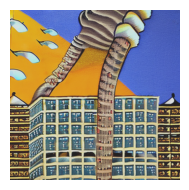

In [12]:
print("Init image:")
show_image(init_image_1)

In [ ]:
init_image_1.shape

## Experiment with Mutations + Gradients

In [ ]:
new_images = []
new_genotypes = []

iso_sigmas = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 0.75, 1.0, 5.0, 10.0]

for iso in iso_sigmas:
    key, subkey = jax.random.split(key)
    new_genotype = isoline_variation(
        init_prompt_embedding_jnp,
        init_prompt_embedding2_jnp,
        key=subkey,
        iso_sigma=iso,
        line_sigma=0.0,
    )
    new_image = generate_images_from_latents(
        init_latent,
        new_genotype,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        scheduler=scheduler,
        unet=unet,
        vae=vae,
    ).squeeze()

    new_images.append(new_image)
    new_genotypes.append(new_genotype)
    print("New image with isoline variation sigma", iso, ":")
    show_image(new_image)

In [ ]:
learning_rates = [1e-2, 5e-3, 1e-3, 5e-4]
steps = [5, 10, 20]


In [ ]:
after_grad_new_genotypes = []
after_grad_new_images = []


for i, new_genotype in enumerate(new_genotypes[5:]):
    print("---- IMAGE: Isoline:", iso_sigmas[5:][i], "----")
    for lr in learning_rates:
        for s in steps:
            new_grad_genotype, new_grad_image = apply_gradient_steps(np.array(new_genotype), lr, s)
            after_grad_new_genotypes.append(new_grad_genotype)
            after_grad_new_images.append(new_grad_image)
            print(f"Image with learning rate {lr} and {s} steps:")
            show_image(new_grad_image)


## Experimenting with Renormalisation

In [ ]:
new_images = []
new_genotypes = []

iso_sigmas = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 0.75, 1.0, 5.0, 10.0]

for iso in iso_sigmas:
    key, subkey = jax.random.split(key)
    new_genotype = isoline_variation(
        init_prompt_embedding_jnp,
        init_prompt_embedding2_jnp,
        key=subkey,
        iso_sigma=iso,
        line_sigma=0.0,
    )
    new_genotype = renorm_tokens(new_genotype, init_prompt_embedding_jnp)
    new_image = generate_images_from_latents(
        init_latent,
        new_genotype,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        scheduler=scheduler,
        unet=unet,
        vae=vae,
    ).squeeze()

    new_images.append(new_image)
    new_genotypes.append(new_genotype)
    print("New image with isoline variation sigma", iso, ":")
    show_image(new_image)

## Experimenting with SLERP

In [ ]:
embedding_1 = new_genotypes[5]
embedding_2 = new_genotypes[7]

In [ ]:
test_slerp(init_prompt_embedding_jnp, embedding_1, [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0, 1.05])

In [ ]:
test_slerp(init_prompt_embedding_jnp, embedding_2, [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0, 1.05])

In [ ]:
test_slerp(embedding_1, embedding_2, [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0, 1.05])

In [ ]:
slerped_genotypes = test_slerp(embedding_1, embedding_2, [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0, 1.05])

In [ ]:
test_lerp(init_prompt_embedding_jnp, embedding_1, [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0, 1.05])

In [ ]:
test_lerp(init_prompt_embedding_jnp, embedding_2, [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0, 1.05])

In [ ]:
test_lerp(embedding_1, embedding_2, [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0, 1.05])

## Experimenting with Mutation of Unconditional Embeddings

In [ ]:
init_image = generate_images_from_latents(init_latent,
            init_prompt_embedding_jnp,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()

show_image(init_image)


In [ ]:
import jax
import jax.numpy as jnp
from typing import Optional, Tuple

def renorm_tokens_jnp(E: jnp.ndarray, ref: jnp.ndarray, eps: float = 1e-8) -> jnp.ndarray:
    """Per-token renormalization to match ref norms. Works for [..., D]."""
    curr = jnp.linalg.norm(E, axis=-1, keepdims=True)
    target = jnp.linalg.norm(ref, axis=-1, keepdims=True)
    scale = target / jnp.maximum(curr, eps)
    return E * scale

def joint_and_together_noise_jnp(
    key,                                # RNG key (jax.random.key(...))
    E_pack: jnp.ndarray,                # [..., 2, S, D]  order: [uncond, cond]
    sigma: float = 0.05,
    token_mask: Optional[jnp.ndarray] = None,  # [..., S] or [..., S, 1]
    renorm: bool = True,
) -> Tuple[jnp.ndarray, jnp.ndarray, jax.Array]:
    """
    Returns:
      posneg   : [..., 2, S, D]  (uncond -= ε, cond += ε)
      together : [..., 2, S, D]  (uncond += ε, cond += ε)
      key_next : new RNG key (so you don't reuse randomness)

    Notes:
      - If you supply token_mask, noise is applied only where mask==1/True.
      - Per-token renorm keeps the original magnitudes, preserving semantics while avoiding
        attention logit blow-ups due to norm drift.
    """
    # split RNG so posneg & together use independent noise
    key, k1, k2 = jax.random.split(key, 3)

    E_un, E_co = E_pack[..., 0, :, :], E_pack[..., 1, :, :]  # [..., S, D]

    # draw noise
    eps_posneg = jax.random.normal(k1, shape=E_un.shape, dtype=E_un.dtype) * sigma
    eps_together = jax.random.normal(k2, shape=E_un.shape, dtype=E_un.dtype) * sigma * 2

    # optional masking
    if token_mask is not None:
        m = token_mask.astype(E_un.dtype)
        if m.ndim == E_un.ndim - 1:   # e.g., [..., S]
            m = m[..., None]          # -> [..., S, 1]
        eps_posneg = eps_posneg * m
        eps_together = eps_together * m

    # --- variant 1: joint pos/neg (widen the cond–uncond contrast) ---
    E_un_posneg = E_un - eps_posneg
    E_co_posneg = E_co + eps_posneg
    if renorm:
        E_un_posneg = renorm_tokens_jnp(E_un_posneg, E_un)
        E_co_posneg = renorm_tokens_jnp(E_co_posneg, E_co)
    posneg = jnp.stack([E_un_posneg, E_co_posneg], axis=-3)     # [..., 2, S, D]

    # --- variant 2: mutate both branches together (keep contrast roughly constant) ---
    E_un_together = E_un + eps_together
    E_co_together = E_co + eps_together
    if renorm:
        E_un_together = renorm_tokens_jnp(E_un_together, E_un)
        E_co_together = renorm_tokens_jnp(E_co_together, E_co)
    together = jnp.stack([E_un_together, E_co_together], axis=-3)  # [..., 2, S, D]

    return posneg, together, key

In [ ]:
prompt_embeddings = jnp.stack([init_prompt_embedding_jnp, init_prompt_embedding_jnp, init_prompt_embedding_jnp], axis=0)  # [B, 2, C, D]
prompt_embeddings.shape

In [ ]:
key, subkey = jax.random.split(key)
new_posneg_genotypes, new_pos_genotypes, key = joint_and_together_noise_jnp(subkey, prompt_embeddings, sigma=0.1, renorm=True)

In [ ]:

for i in range(3):
    new_image = generate_images_from_latents(
            init_latent,
            new_posneg_genotypes[i],
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()

    print(f"Image with joint posneg noise, genotype {i}:")
    show_image(new_image)
    
    new_unjoint_image = generate_images_from_latents(
            init_latent,
            new_pos_genotypes[i],
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()
    
    print(f"Image with unjoint posneg noise, genotype {i}:")
    show_image(new_unjoint_image)


In [ ]:
after_grad_new_genotypes = []
after_grad_new_images = []

learning_rates = [5e-3]
steps = [10]

for i, new_genotype in enumerate(new_posneg_genotypes):
    for lr in learning_rates:
        for s in steps:
            new_grad_genotype, new_grad_image = apply_gradient_steps(np.array(new_genotype), lr, s)
            after_grad_new_genotypes.append(new_grad_genotype)
            after_grad_new_images.append(new_grad_image)
            print(f"Image with learning rate {lr} and {s} steps:")
            show_image(new_grad_image)


In [ ]:


key, subkey = jax.random.split(key)
new_posneg_genotypes, new_pos_genotypes, key = joint_and_together_noise_jnp(subkey, prompt_embeddings, sigma=0.5, renorm=True)

for i in range(3):
    new_image = generate_images_from_latents(
            init_latent,
            new_posneg_genotypes[i],
            num_inference_steps=num_inference_steps,
            guidance_scale=4,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()

    print(f"Image with joint posneg noise, genotype {i}:")
    show_image(new_image)
    
    new_unjoint_image = generate_images_from_latents(
            init_latent,
            new_pos_genotypes[i],
            num_inference_steps=num_inference_steps,
            guidance_scale=4,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()
    
    print(f"Image with unjoint posneg noise, genotype {i}:")
    show_image(new_unjoint_image)

In [ ]:
after_grad_new_genotypes = []
after_grad_new_images = []

learning_rates = [5e-3]
steps = [1]

for i, new_genotype in enumerate(new_posneg_genotypes):
    for lr in learning_rates:
        for s in steps:
            new_grad_genotype, new_grad_image = apply_gradient_steps(np.array(new_genotype), lr, s)
            after_grad_new_genotypes.append(new_grad_genotype)
            after_grad_new_images.append(new_grad_image)
            print(f"Image with learning rate {lr} and {s} steps:")
            show_image(new_grad_image)


## Experiment with per-word Mutations

In [ ]:
def pad_mask_from_input_ids(input_ids: torch.Tensor, pad_token_id: int) -> torch.Tensor:
    """
    Create a mask for non-padding tokens.
    
    Args:
        input_ids: LongTensor [B, S] from tokenizer
        pad_token_id: usually tokenizer.pad_token_id
        
    Returns:
        mask: BoolTensor [B, S]  (True = real token, False = pad)
        
    """
    pytorch_mask = input_ids != pad_token_id
    return jnp.array(pytorch_mask.numpy(), dtype=jnp.bool_)

ti = tokenizer([prompt], padding="max_length", max_length=77, return_tensors="pt")
padding_mask = pad_mask_from_input_ids(ti.input_ids, tokenizer.pad_token_id)  # [B, S]


In [ ]:
def find_phrase_mask(
    tokenizer,
    prompt: str,
    phrase: str,
    max_length: int = 77,
    device="cpu",
):
    """
    Find token mask for phrase inside prompt.
    
    Args:
        tokenizer: HuggingFace tokenizer (CLIPTokenizer etc.)
        prompt: full prompt string
        phrase: substring/phrase to locate
        max_length: tokenizer sequence length (77 for SD)
        
    Returns:
        mask: torch.BoolTensor [S], True where tokens belong to phrase
        input_ids: torch.LongTensor [S], token IDs for the full prompt
    """
    # tokenize both
    ids_prompt = tokenizer(prompt, padding="max_length", truncation=True,
                           max_length=max_length, return_tensors="pt").input_ids[0]
    ids_phrase = tokenizer(phrase, padding="max_length", truncation=True,
                           max_length=max_length, return_tensors="pt").input_ids[0]

    bos, eos, pad = tokenizer.bos_token_id, tokenizer.eos_token_id, tokenizer.pad_token_id
    # strip special tokens from phrase
    ids_phrase_stripped = [t.item() for t in ids_phrase if t not in (bos, eos, pad)]

    # find subsequence
    spans = []
    for i in range(len(ids_prompt) - len(ids_phrase_stripped) + 1):
        if ids_prompt[i:i+len(ids_phrase_stripped)].tolist() == ids_phrase_stripped:
            spans.append((i, i+len(ids_phrase_stripped)))

    # build mask
    mask = torch.zeros_like(ids_prompt, dtype=torch.bool)
    for s, e in spans:
        mask[s:e] = True

    return mask.to(device), ids_prompt

def phrase_mask_for_embeddings(
    jnp_embeddings: jnp.ndarray,   # shape [S,D] or [B,S,D]
    tokenizer,
    prompt: str,
    phrase: str,
    max_length: int = 77,
):
    """
    Return a boolean mask in jnp aligned to embeddings for the phrase tokens.
    """
    mask_torch, ids_prompt = find_phrase_mask(tokenizer, prompt, phrase, max_length=max_length)
    # convert torch mask → numpy → jnp
    mask_np = mask_torch.cpu().numpy()
    mask_jnp = jnp.asarray(mask_np)
    if jnp_embeddings.ndim == 3:
        # expand to [B,S,1] broadcast
        mask_jnp = jnp.broadcast_to(mask_jnp, jnp_embeddings.shape[:2])
    return mask_jnp

In [ ]:
key, subkey = jax.random.split(key)
new_posneg_genotypes, new_pos_genotypes, key = joint_and_together_noise_jnp(subkey, prompt_embeddings, sigma=0.05, token_mask=padding_mask, renorm=True)

for i in range(3):
    new_image = generate_images_from_latents(
            init_latent,
            new_posneg_genotypes[i],
            num_inference_steps=num_inference_steps,
            guidance_scale=7.5,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()

    print(f"Image with joint posneg noise, genotype {i}:")
    show_image(new_image)
    
    new_unjoint_image = generate_images_from_latents(
            init_latent,
            new_pos_genotypes[i],
            num_inference_steps=num_inference_steps,
            guidance_scale=7.5,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()
    
    print(f"Image with unjoint posneg noise, genotype {i}:")
    show_image(new_unjoint_image)

In [ ]:
prompt

In [ ]:
def broadcast_token_mask_to_embeddings(mask, embeddings):
    """
    Make a token mask broadcastable to the last-two axes of embeddings.
    
    embeddings: jnp.ndarray with shape
        - [B, S, D]            or
        - [B, 2, S, D]        (branch axis = 1; typical [uncond, cond])
    mask: token mask with shape one of:
        - [S]                  (applies to all batch/branches)
        - [B, S]               (per-sample)
        - [S, 1] or [B, S, 1]  (already has trailing singleton)
        - For [B, 2, S, D], you can also pass [B, 1, S] or [B, 2, S]
    
    Returns:
        mask_broadcast: jnp.ndarray broadcastable to embeddings with shape
            - [B, S, 1]        for [B, S, D]
            - [B, 2, S, 1]     for [B, 2, S, D]
    """
    E = embeddings
    m = jnp.asarray(mask)
    if E.ndim == 3:
        B, S, D = E.shape
        if m.ndim == 1:            # [S]
            assert m.shape[0] == S
            m = m[None, :, None]   # -> [1, S, 1]
        elif m.ndim == 2:          # [B, S]
            assert m.shape == (B, S)
            m = m[..., None]       # -> [B, S, 1]
        elif m.ndim == 3:
            # expect [B, S, 1] or [1, S, 1]
            assert m.shape[-2] == S and m.shape[-1] == 1
        else:
            raise ValueError(f"Incompatible mask shape {m.shape} for embeddings {E.shape}")
        return m.astype(E.dtype)
    elif E.ndim == 4:
        B, two, S, D = E.shape
        assert two == 2, "Expected embeddings shape [B, 2, S, D]"
        if m.ndim == 1:            # [S]
            assert m.shape[0] == S
            m = m[None, None, :, None]   # -> [1, 1, S, 1] (applies to both branches)
        elif m.ndim == 2:          # [B, S]
            assert m.shape == (B, S)
            m = m[:, None, :, None]      # -> [B, 1, S, 1]
        elif m.ndim == 3:
            # [B, 1, S] or [B, 2, S]
            assert m.shape[-1] == S
            m = m[..., None]             # -> [B, 1/2, S, 1]
        elif m.ndim == 4:
            # [B, 2, S, 1] or [1, 2, S, 1]
            assert m.shape[-2] == S and m.shape[-1] == 1
        else:
            raise ValueError(f"Incompatible mask shape {m.shape} for embeddings {E.shape}")
        return m.astype(E.dtype)
    else:
        raise ValueError(f"Unsupported embeddings ndim {E.ndim}; expected 3 or 4")

In [ ]:
phrase = "tornado made of tigers"

phrase_mask = phrase_mask_for_embeddings(
    prompt_embeddings,
    tokenizer,
    prompt,
    phrase,
    max_length=77,
)

phrase_mask = broadcast_token_mask_to_embeddings(phrase_mask, prompt_embeddings)
    
key, subkey = jax.random.split(key)
new_posneg_genotypes, new_pos_genotypes, key = joint_and_together_noise_jnp(subkey, prompt_embeddings, sigma=0.5, token_mask=phrase_mask, renorm=True)

new_posneg_genotypes = new_posneg_genotypes.squeeze(axis=0)  # [B, S, D]
new_pos_genotypes = new_pos_genotypes.squeeze(axis=0)       

for i in range(3):
    new_image = generate_images_from_latents(
            init_latent,
            new_posneg_genotypes[i],
            num_inference_steps=num_inference_steps,
            guidance_scale=7.5,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()

    print(f"Image with joint posneg noise, genotype {i}:")
    show_image(new_image)
    
    new_unjoint_image = generate_images_from_latents(
            init_latent,
            new_pos_genotypes[i],
            num_inference_steps=num_inference_steps,
            guidance_scale=7.5,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()
    
    print(f"Image with unjoint posneg noise, genotype {i}:")
    show_image(new_unjoint_image)

## Adding tokens mid-sentence

In [13]:
import random
from typing import List, Tuple, Dict, Optional

import numpy as np
import torch
import jax
import jax.numpy as jnp

# -------------------------
# Helpers: tokenizer / split / gap
# -------------------------

def _first_idx(seq, token_id: int) -> int:
    for i, t in enumerate(seq):
        if int(t) == int(token_id):
            return i
    return -1

def _strip_special(ids: List[int], bos: int, eos: int, pad: int) -> List[int]:
    return [int(t) for t in ids if int(t) not in (bos, eos, pad)]

def _find_subseq_spans(hay: List[int], needle: List[int]) -> List[Tuple[int, int]]:
    spans = []
    H, N = len(hay), len(needle)
    if N == 0:
        return spans
    for i in range(H - N + 1):
        if hay[i:i+N] == needle:
            spans.append((i, i+N))
    return spans

def split_prompt_insert_gap(
    tokenizer,
    prompt: str,
    split_phrase: str | None = "a small",
    placeholder: str = ".",   # neutral token
    gap_len: int = 1,
    max_length: int = 77,
    rng: random.Random | None = None,
):
    """
    Split prompt after split_phrase (if provided) or a random word if None,
    then insert `gap_len` placeholder tokens.

    Returns:
      input_ids: torch.LongTensor [S]
      gap_mask: torch.BoolTensor [S]
      nonpad_mask: torch.BoolTensor [S]
      split_info: torch.LongTensor [2] (start,end) if phrase found, else (-1,-1)
      bos_eos_pad: torch.LongTensor [3] (ids)
    """
    if rng is None:
        rng = random

    ti = tokenizer(prompt, padding="max_length", truncation=True,
                   max_length=max_length, return_tensors="pt")
    ids = ti.input_ids[0].tolist()
    bos, eos, pad = tokenizer.bos_token_id, tokenizer.eos_token_id, tokenizer.pad_token_id

    # find first EOS or PAD
    eos_idx = ids.index(eos) if eos in ids else max_length
    pad_idx = ids.index(pad) if pad in ids else max_length
    end_idx = min(eos_idx, pad_idx)

    content = ids[1:end_idx]  # exclude BOS, stop before EOS/PAD

    # Tokenize placeholder
    t_placeholder = tokenizer(placeholder, padding="do_not_pad", return_tensors="pt").input_ids[0].tolist()
    t_placeholder = [tid for tid in t_placeholder if tid not in (bos, eos, pad)]

    split_pos = None
    split_info = (-1, -1)

    if split_phrase is not None:
        # tokenize split phrase
        t_phrase = tokenizer(split_phrase, padding="max_length", truncation=True,
                             max_length=max_length, return_tensors="pt").input_ids[0].tolist()
        phrase_ids = [tid for tid in t_phrase if tid not in (bos, eos, pad)]

        # try to find phrase in content
        spans = []
        H, N = len(content), len(phrase_ids)
        for i in range(H - N + 1):
            if content[i:i+N] == phrase_ids:
                spans.append((i, i+N))

        if spans:
            s, e = spans[0]
            split_pos = e
            split_info = (s, e)

    if split_pos is None:
        # fallback: random split on a word in content
        if len(content) <= 2:
            split_pos = max(1, len(content) // 2)
        else:
            split_pos = rng.randint(1, len(content) - 1)
        split_info = (-1, -1)

    # reassemble with placeholder gap
    pre = content[:split_pos]
    post = content[split_pos:]
    gap_tokens = (t_placeholder or [pad]) * gap_len

    new = [bos] + pre + gap_tokens + post + [eos]
    new = new[:max_length]
    if len(new) < max_length:
        new += [pad] * (max_length - len(new))

    input_ids = torch.tensor(new, dtype=torch.long)

    # gap mask
    gap_mask = torch.zeros(max_length, dtype=torch.bool)
    gap_start = 1 + len(pre)
    gap_end   = min(gap_start + gap_len, max_length-1)
    eos_pos_new = new.index(eos) if eos in new else None
    if eos_pos_new is not None:
        gap_end = min(gap_end, eos_pos_new)
    if gap_end > gap_start:
        gap_mask[gap_start:gap_end] = True

    nonpad_mask = (input_ids != pad)

    return {
        "input_ids": input_ids,
        "gap_mask": gap_mask,
        "nonpad_mask": nonpad_mask,
        "split_info": torch.tensor(split_info, dtype=torch.long),
        "bos_eos_pad": torch.tensor([bos, eos, pad], dtype=torch.long),
    }

In [14]:

def renorm_tokens_jnp(E: jnp.ndarray, ref: jnp.ndarray, eps: float = 1e-8) -> jnp.ndarray:
    curr = jnp.linalg.norm(E, axis=-1, keepdims=True)
    target = jnp.linalg.norm(ref, axis=-1, keepdims=True)
    return E * (target / jnp.maximum(curr, eps))

def mutate_gap_jax(
    key,
    E_cond_jnp: jnp.ndarray,     # [S, D] (cond embeddings)
    gap_mask_1d: jnp.ndarray,    # [S] boolean
    sigma: float = 0.07,
    renorm_to_ref: bool = True,
) -> jnp.ndarray:
    """Add Gaussian noise only on gap tokens; optional renorm to original cond norms."""
    S, D = E_cond_jnp.shape
    mask = gap_mask_1d.astype(E_cond_jnp.dtype).reshape(S, 1)  # [S,1]
    key, sub = jax.random.split(key)
    noise = jax.random.normal(sub, shape=(S, D), dtype=E_cond_jnp.dtype) * sigma
    E_mut = E_cond_jnp + noise * mask
    if renorm_to_ref:
        E_mut = renorm_tokens_jnp(E_mut, E_cond_jnp)
    return E_mut

# -------------------------
# Torch <-> JAX bridges
# -------------------------

def jnp_to_torch(x: jnp.ndarray, device, dtype) -> torch.Tensor:
    return torch.from_numpy(np.array(x)).to(device=device, dtype=dtype)

def torch_to_jnp(x: torch.Tensor) -> jnp.ndarray:
    return jnp.asarray(x.detach().cpu().numpy())

# -------------------------
# Assemble encoder_hidden_states for CFG
# -------------------------

def assemble_encoder_hidden_states(
    cond_emb: torch.Tensor,          # [S, D] or [1, S, D]
    uncond_emb: torch.Tensor,        # [S, D] or [1, S, D]
    batch_size: int = 1,
) -> torch.Tensor:
    """
    Returns encoder_hidden_states shaped [batch_size*2, S, D]
    Order: [uncond, cond] per batch sample.
    """
    if cond_emb.ndim == 3 and cond_emb.shape[0] == 1: cond_emb = cond_emb[0]
    if uncond_emb.ndim == 3 and uncond_emb.shape[0] == 1: uncond_emb = uncond_emb[0]
    assert cond_emb.shape == uncond_emb.shape and cond_emb.ndim == 2, \
        f"Need [S,D]; got cond {cond_emb.shape}, uncond {uncond_emb.shape}"

    pair = torch.stack([uncond_emb, cond_emb], dim=0)  # [2, S, D]
    if batch_size > 1:
        pair = pair.unsqueeze(0).expand(batch_size, -1, -1, -1)  # [B,2,S,D]
        pair = pair.reshape(batch_size * 2, *pair.shape[2:])     # [B*2,S,D]
    return pair

def to_jnp_mask(mask, S, dtype=jnp.float32):
    """Convert mask to jnp array and broadcast to [S,1]."""
    if isinstance(mask, torch.Tensor):
        mask = mask.detach().cpu().numpy()
    mask = jnp.asarray(mask)          # handles list / np / jnp
    if mask.ndim == 0:
        raise ValueError("Mask must be 1D or 2D over tokens.")
    if mask.ndim == 2 and mask.shape[-1] == 1 and mask.shape[-2] == S:
        return mask.astype(dtype)     # already [S,1]
    if mask.ndim == 1:
        assert mask.shape[0] == S, f"Mask length {mask.shape[0]} != S {S}"
        return mask.astype(dtype).reshape(S, 1)
    raise ValueError(f"Unsupported mask shape {mask.shape}; expected [S] or [S,1].")

def renorm_tokens_jnp(E: jnp.ndarray, ref: jnp.ndarray, eps: float = 1e-8) -> jnp.ndarray:
    curr = jnp.linalg.norm(E, axis=-1, keepdims=True)
    target = jnp.linalg.norm(ref, axis=-1, keepdims=True)
    return E * (target / jnp.maximum(curr, eps))

def mutate_masked_jax(
    key,
    E: jnp.ndarray,           # [S, D]
    mask,                     # [S] or [S,1] (list/torch/np/jnp OK)
    sigma: float = 0.05,
    renorm_to_ref: jnp.ndarray | None = None,  # None = no renorm; otherwise per-token to 'ref'
):
    S, D = E.shape
    m = to_jnp_mask(mask, S, dtype=E.dtype)    # -> [S,1]
    key, sub = jax.random.split(key)
    noise = jax.random.normal(sub, shape=(S, D), dtype=E.dtype) * sigma
    out = E + noise * m
    if renorm_to_ref is not None:
        out = renorm_tokens_jnp(out, renorm_to_ref)
    return out, key

def build_word_mask_jnp(ids_torch: torch.Tensor, bos_id: int, eos_id: int, pad_id: int):
    """
    ids_torch: [S] torch.LongTensor (your ids_new)
    Returns jnp.bool_ [S]: True for 'word tokens' (not BOS/EOS/PAD).
    """
    ids = ids_torch.detach().cpu()
    is_pad  = (ids == pad_id)
    is_bos  = (ids == bos_id)
    is_eos  = (ids == eos_id)
    m = ~(is_pad | is_bos | is_eos)       # keep everything else
    return jnp.asarray(m.numpy(), dtype=bool)  # [S]


In [15]:
import torch
import re
import string

@torch.no_grad()
def collect_vocab_stats(tokenizer, text_encoder, max_length=77, device="cuda"):
    """
    Returns:
      mu:   [D] mean of token vectors (position-agnostic)
      sigma:[D] per-dim std
      norm_med: scalar median L2 norm over tokens
      kept_token_ids: list[int] we used (good to reuse/filter later)
    """
    vocab = tokenizer.get_vocab()          # str -> id
    inv_vocab = {i: s for s, i in vocab.items()}

    specials = {tokenizer.pad_token_id,
                tokenizer.eos_token_id,
                tokenizer.bos_token_id}

    # crude punctuation filter
    def is_punct(tok: str) -> bool:
        tok = tok.strip()
        return (len(tok) == 0) or all(ch in string.punctuation for ch in tok)

    kept = []
    for tid, tok in inv_vocab.items():
        if tid in specials:
            continue
        if is_punct(tok):
            continue
        kept.append(tid)

    D = None
    embeds = []
    for tid in kept:
        ids = torch.full((max_length,), tokenizer.pad_token_id, dtype=torch.long)
        ids[0] = tokenizer.bos_token_id
        ids[1] = tid
        ids[2] = tokenizer.eos_token_id
        ids = ids.unsqueeze(0).to(device)  # [1,S]

        out = text_encoder(input_ids=ids)
        if isinstance(out, tuple):
            E = out[0]
        elif hasattr(out, "last_hidden_state"):
            E = out.last_hidden_state
        else:
            E = out
        v = E[0, 1]  # embedding at pos=1
        if D is None:
            D = v.shape[-1]
        embeds.append(v)

    M = torch.stack(embeds, dim=0)   # [N,D]
    mu    = M.mean(dim=0)            # [D]
    sigma = M.std(dim=0, unbiased=True)
    norms = torch.linalg.vector_norm(M, dim=-1)
    norm_med = norms.median()
    return mu, sigma, norm_med.item(), kept


@torch.no_grad()
def make_neutral_embedding(
    mu: torch.Tensor,
    sigma_vec: torch.Tensor,
    target_norm: float,
    noise_scale: float = 0.3,
) -> torch.Tensor:
    """
    Sample v ~ N(mu, (noise_scale*sigma_vec)^2), then L2-renorm to target_norm.
    Returns [D] on mu.device with mu.dtype.
    """
    device, dtype = mu.device, mu.dtype
    v = mu + torch.randn_like(mu, device=device, dtype=dtype) * (noise_scale * sigma_vec)
    v = v / (v.norm() + 1e-8) * float(target_norm)
    return v

In [ ]:
prompt = "a box on a glass table"
init_genotype = get_text_embeddings(
    prompt=prompt,
    batch_size=1,  # type: ignore
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    with_grad=False,  # No gradients needed for initial image generation
)

init_image_1 = generate_images_from_latents(
    init_latent,
    init_genotype,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
).squeeze()

show_image(init_image_1)

In [16]:
import os, json, hashlib, time
from typing import Tuple, List, Optional, Dict, Any
import torch

def _tokenizer_fingerprint(tokenizer) -> str:
    """
    Build a stable-ish fingerprint of the tokenizer config & vocab.
    Recompute stats if this changes.
    """
    meta = {
        "class": tokenizer.__class__.__name__,
        "name_or_path": getattr(tokenizer, "name_or_path", ""),
        "vocab_size": getattr(tokenizer, "vocab_size", None),
        "bos_id": getattr(tokenizer, "bos_token_id", None),
        "eos_id": getattr(tokenizer, "eos_token_id", None),
        "pad_id": getattr(tokenizer, "pad_token_id", None),
    }
    # also hash the vocab mapping if available (can be large; ok once)
    try:
        vocab = tokenizer.get_vocab()  # dict[str->int]
        # hash of concatenated "token:int" pairs sorted by token
        h = hashlib.sha256()
        for k in sorted(vocab.keys()):
            h.update(f"{k}:{vocab[k]}".encode("utf-8"))
        meta["vocab_hash"] = h.hexdigest()
    except Exception:
        meta["vocab_hash"] = ""
    return hashlib.sha256(json.dumps(meta, sort_keys=True).encode("utf-8")).hexdigest()

def save_neutral_stats(
    path: str,
    mu_vec: torch.Tensor,
    sigma_vec: torch.Tensor,
    norm_med: float,
    kept_ids: List[int],
    tokenizer_fingerprint: str,
    extra_meta: Optional[Dict[str, Any]] = None,
) -> None:
    """
    Saves everything in a single .pt file (torch.save) with CPU tensors.
    """
    payload = {
        "mu_vec": mu_vec.detach().cpu(),
        "sigma_vec": sigma_vec.detach().cpu(),
        "norm_med": float(norm_med),
        "kept_ids": kept_ids,
        "tokenizer_fingerprint": tokenizer_fingerprint,
        "meta": {
            "saved_at": time.time(),
            **(extra_meta or {}),
        },
    }
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    torch.save(payload, path)

def load_neutral_stats(
    path: str,
    tokenizer_fingerprint: str,
    device: Optional[str] = None,
    dtype: Optional[torch.dtype] = None,
) -> Optional[Tuple[torch.Tensor, torch.Tensor, float, List[int]]]:
    """
    Loads and validates; returns (mu_vec, sigma_vec, norm_med, kept_ids) or None if mismatch/missing.
    """
    if not os.path.exists(path):
        return None
    payload = torch.load(path, map_location="cpu")
    if payload.get("tokenizer_fingerprint", "") != tokenizer_fingerprint:
        return None  # tokenizer changed; recompute
    mu = payload["mu_vec"]
    sg = payload["sigma_vec"]
    if dtype is not None:
        mu = mu.to(dtype=dtype)
        sg = sg.to(dtype=dtype)
    if device is not None:
        mu = mu.to(device)
        sg = sg.to(device)
    return mu, sg, float(payload["norm_med"]), list(payload["kept_ids"])


def get_or_build_neutral_stats(
    cache_path: str,
    tokenizer,
    text_encoder,
    max_length: int = 77,
    device: str = "cuda",
    dtype: torch.dtype = torch.float32,
):
    fp = _tokenizer_fingerprint(tokenizer)
    loaded = load_neutral_stats(cache_path, fp, device=device, dtype=dtype)
    if loaded is not None:
        return loaded  # (mu_vec, sigma_vec, norm_med, kept_ids)

    # not cached or fingerprint mismatch → compute once
    mu_vec, sigma_vec, norm_med, kept_ids = collect_vocab_stats(
        tokenizer=tokenizer,
        text_encoder=text_encoder,
        max_length=max_length,
        device=device,
    )
    save_neutral_stats(
        cache_path,
        mu_vec=mu_vec,
        sigma_vec=sigma_vec,
        norm_med=norm_med,
        kept_ids=kept_ids,
        tokenizer_fingerprint=fp,
        extra_meta={"max_length": max_length},
    )
    # move to requested dtype/device
    mu_vec  = mu_vec.to(device=device, dtype=dtype)
    sigma_vec = sigma_vec.to(device=device, dtype=dtype)
    return mu_vec, sigma_vec, norm_med, kept_ids

# pick a cache file location
cache_file = "./neutral_stats.pt"

mu_vec, sigma_vec, norm_med, kept_ids = get_or_build_neutral_stats(
    cache_path=cache_file,
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    max_length=77,
    device="cuda",
    dtype=torch.float32,
)

In [41]:
# ==============================
# Build M, fit PCA, cache to disk
# ==============================
import os, json, hashlib, time, string
from typing import List, Dict, Optional, Tuple
import torch

# ---------- small utils ----------
def _tokenizer_fingerprint(tokenizer) -> str:
    meta = {
        "class": tokenizer.__class__.__name__,
        "name_or_path": getattr(tokenizer, "name_or_path", ""),
        "vocab_size": getattr(tokenizer, "vocab_size", None),
        "bos_id": getattr(tokenizer, "bos_token_id", None),
        "eos_id": getattr(tokenizer, "eos_token_id", None),
        "pad_id": getattr(tokenizer, "pad_token_id", None),
    }
    try:
        vocab = tokenizer.get_vocab()  # str -> id
        h = hashlib.sha256()
        for k in sorted(vocab.keys()):
            h.update(f"{k}:{vocab[k]}".encode("utf-8"))
        meta["vocab_hash"] = h.hexdigest()
    except Exception:
        meta["vocab_hash"] = ""
    return hashlib.sha256(json.dumps(meta, sort_keys=True).encode("utf-8")).hexdigest()

def _is_punct(tok: str) -> bool:
    tok = tok.strip()
    return (len(tok) == 0) or all(ch in string.punctuation for ch in tok)

# ---------- build token-embedding corpus M [N, D] ----------
@torch.no_grad()
def build_token_matrix_batched(
    tokenizer,
    text_encoder,
    max_length: int = 77,
    device: str = "cuda",
    batch_size: int = 512,
) -> Tuple[torch.Tensor, List[int]]:
    """
    Encodes each (filtered) vocab token at a fixed slot (pos=1 between BOS/EOS),
    returning:
      M: [N, D] token embedding matrix
      kept_ids: list[int] token ids used (same order as rows of M)
    """
    vocab = tokenizer.get_vocab()                 # str -> id
    inv_vocab = {i: s for s, i in vocab.items()}
    bos, eos, pad = tokenizer.bos_token_id, tokenizer.eos_token_id, tokenizer.pad_token_id

    kept_ids: List[int] = []
    for tid, tok in inv_vocab.items():
        if tid in {bos, eos, pad}:      # skip specials
            continue
        if _is_punct(tok):              # skip pure punctuation/whitespace
            continue
        kept_ids.append(tid)

    # pack into batches
    rows: List[torch.Tensor] = []
    for i in range(0, len(kept_ids), batch_size):
        chunk = kept_ids[i:i+batch_size]
        # Build ids: [B,S] with BOS at 0, token at 1, EOS at 2, rest PAD
        S = max_length
        ids = torch.full((len(chunk), S), pad, dtype=torch.long)
        ids[:, 0] = bos
        ids[:, 1] = torch.tensor(chunk, dtype=torch.long)
        ids[:, 2] = eos
        ids = ids.to(device)

        out = text_encoder(input_ids=ids)
        if isinstance(out, tuple):
            H = out[0]                      # [B,S,D]
        elif hasattr(out, "last_hidden_state"):
            H = out.last_hidden_state       # [B,S,D]
        else:
            H = out                         # assume [B,S,D]

        v = H[:, 1, :]                      # [B,D] take token at pos=1
        rows.append(v.detach().to("cpu"))

    M = torch.cat(rows, dim=0)              # [N, D] on CPU
    return M, kept_ids

# ---------- PCA fit ----------
@torch.no_grad()
def pca_fit(M: torch.Tensor, q: Optional[int] = None, center: bool = True) -> Dict[str, torch.Tensor]:
    """
    Fit PCA to matrix M [N,D] (CPU or GPU).
    Returns dict with:
      mu: [D], V: [D,q], S: [q],
      explained_var [q], explained_ratio [q], cum_ratio [q]
    """
    device, dtype = M.device, M.dtype
    N, D = M.shape
    if center:
        mu = M.mean(dim=0)
        X = M - mu
    else:
        mu = torch.zeros(D, device=device, dtype=dtype)
        X = M
    if q is None:
        q = min(N, D)

    # pca_lowrank can run on GPU if X is on CUDA
    U, S, V = torch.pca_lowrank(X, q=q, center=False)  # V: [D,q]
    explained_var = (S ** 2) / max(N - 1, 1)
    total_var = (X.pow(2).sum() / max(N - 1, 1)).clamp_min(1e-12)
    explained_ratio = explained_var / total_var
    cum_ratio = explained_ratio.cumsum(dim=0)

    return {
        "mu": mu, "V": V, "S": S,
        "explained_var": explained_var,
        "explained_ratio": explained_ratio,
        "cum_ratio": cum_ratio,
    }

# ---------- cache save/load ----------
def save_pca_results(path: str, pca: Dict[str, torch.Tensor], kept_ids: List[int], tokenizer_fp: str):
    payload = {
        "mu": pca["mu"].detach().cpu(),
        "V":  pca["V"].detach().cpu(),
        "S":  pca["S"].detach().cpu(),
        "explained_var": pca["explained_var"].detach().cpu(),
        "explained_ratio": pca["explained_ratio"].detach().cpu(),
        "cum_ratio": pca["cum_ratio"].detach().cpu(),
        "kept_ids": kept_ids,
        "tokenizer_fingerprint": tokenizer_fp,
        "saved_at": time.time(),
    }
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    torch.save(payload, path)

def load_pca_results(path: str, tokenizer_fp: str, device: Optional[str] = None, dtype: Optional[torch.dtype] = None):
    if not os.path.exists(path):
        return None
    payload = torch.load(path, map_location="cpu")
    if payload.get("tokenizer_fingerprint", "") != tokenizer_fp:
        return None
    def td(x):
        if dtype is not None: x = x.to(dtype=dtype)
        if device is not None: x = x.to(device)
        return x
    return {
        "mu": td(payload["mu"]),
        "V":  td(payload["V"]),
        "S":  td(payload["S"]),
        "explained_var": td(payload["explained_var"]),
        "explained_ratio": td(payload["explained_ratio"]),
        "cum_ratio": td(payload["cum_ratio"]),
        "kept_ids": payload["kept_ids"],
    }

# ---------- one-liner: get or build PCA ----------
def get_or_build_pca(
    cache_path: str,
    tokenizer,
    text_encoder,
    *,
    max_length: int = 77,
    device: str = "cuda",
    batch_size: int = 512,
    q: Optional[int] = None,             # how many PCs to compute
    pca_device: Optional[str] = None,    # where to keep PCA tensors after load/build
    pca_dtype: torch.dtype = torch.float32,
):
    fp = _tokenizer_fingerprint(tokenizer)
    loaded = load_pca_results(cache_path, fp, device=pca_device, dtype=pca_dtype) if os.path.exists(cache_path) else None
    if loaded is not None:
        return loaded  # dict with mu,V,S,explained_var,explained_ratio,cum_ratio,kept_ids

    # build M on the fly (GPU text-encoding for speed; M returned on CPU)
    M_cpu, kept_ids = build_token_matrix_batched(
        tokenizer=tokenizer,
        text_encoder=text_encoder,
        max_length=max_length,
        device=device,
        batch_size=batch_size,
    )

    # (optional) move M to GPU for PCA speed if you like:
    M = M_cpu.to(device if pca_device is None else pca_device)

    pca = pca_fit(M, q=q, center=True)
    save_pca_results(cache_path, pca, kept_ids, fp)

    # move to requested device/dtype for downstream use
    for k in ("mu","V","S","explained_var","explained_ratio","cum_ratio"):
        pca[k] = pca[k].to(device=pca_device, dtype=pca_dtype) if pca_device is not None else pca[k].to(dtype=pca_dtype)
    pca["kept_ids"] = kept_ids
    return pca

# choose where to cache
cache_file = "./pca_token_embeddings.pt"

# 1) Build (or load) PCA once
pca = get_or_build_pca(
    cache_path=cache_file,
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    max_length=77,
    device="cuda",          # encode tokens on GPU
    batch_size=512,
    q=256,                  # compute top 256 PCs (tune as you like)
    pca_device="cuda",      # keep PCA tensors on GPU for fast use
    pca_dtype=torch.float32,
)

# 2) Report coverage for your chosen projection dimension k
k = 256
covered = float(pca["cum_ratio"][k-1].item())
print(f"Top-{k} PCs explain ~{covered*100:.2f}% of variance")

Top-256 PCs explain ~65.95% of variance


In [35]:
import torch
import numpy as np
from typing import Any, Dict, Optional, Tuple

@torch.no_grad()
def _to_torch_bool_mask_1d(mask: Any, S: int, device) -> torch.Tensor:
    # Accept torch / numpy / jax / list -> torch.bool [S]
    if isinstance(mask, torch.Tensor):
        m = mask
    else:
        try:
            # jax arrays show up here fine as np.array(mask)
            m = torch.as_tensor(np.array(mask))
        except Exception:
            m = torch.as_tensor(mask)
    if m.ndim != 1 or m.shape[0] != S:
        raise ValueError(f"mask must be [S], got {tuple(m.shape)}")
    return m.to(device=device, dtype=torch.bool)

@torch.no_grad()
def pca_project(E: torch.Tensor, mu: torch.Tensor, V_k: torch.Tensor) -> torch.Tensor:
    return (E - mu) @ V_k  # [..., k]

@torch.no_grad()
def pca_reconstruct(c: torch.Tensor, mu: torch.Tensor, V_k: torch.Tensor) -> torch.Tensor:
    return mu + c @ V_k.T  # [..., D]

@torch.no_grad()
def mutate_lowdim(c: torch.Tensor, *, sigma: float = 0.0, scale: Optional[float] = None) -> torch.Tensor:
    out = c
    if sigma and sigma > 0:
        out = out + torch.randn_like(out) * float(sigma)
    if scale is not None:
        out = out * float(scale)
    return out

@torch.no_grad()
def pca_edit_masked(
    E: torch.Tensor,                 # [S, D] torch
    mask_1d,                         # [S] mask (torch/np/jax/list ok)
    pca: Dict[str, Any],             # dict with "mu","V","cum_ratio" (torch or np)
    k: int,                          # projection dimension to use
    *,
    sigma: float = 0.0,              # noise in low-D
    scale: Optional[float] = None,   # multiplicative scale in low-D
    return_variance_info: bool = True,
) -> Tuple[torch.Tensor, Optional[float]]:
    """
    Project ONLY masked tokens into top-k PC space, mutate there, reconstruct, and merge back.
    Unmasked rows are unchanged. Returns (E_new, cumulative_explained_ratio_for_k).
    """
    assert E.ndim == 2, "E must be [S, D]"
    S, D = E.shape
    device, dtype = E.device, E.dtype

    # --- coerce PCA tensors safely (two-step .to to avoid numpy dtype issues) ---
    mu = pca["mu"]
    V  = pca["V"]
    # Accept numpy arrays too:
    if not isinstance(mu, torch.Tensor): mu = torch.as_tensor(mu)
    if not isinstance(V,  torch.Tensor): V  = torch.as_tensor(V)

    mu = mu.to(device=device)         # step 1: device
    V  = V.to(device=device)
    mu = mu.to(dtype=dtype)           # step 2: dtype
    V  = V.to(dtype=dtype)

    # cum_ratio can stay float32; just make sure it's a torch tensor
    cum_ratio = pca.get("cum_ratio", None)
    if cum_ratio is not None and not isinstance(cum_ratio, torch.Tensor):
        cum_ratio = torch.as_tensor(cum_ratio, device=device, dtype=torch.float32)
    elif isinstance(cum_ratio, torch.Tensor):
        cum_ratio = cum_ratio.to(device=device, dtype=torch.float32)

    if not (1 <= k <= V.shape[1]):
        raise ValueError(f"k must be in [1, {V.shape[1]}], got {k}")
    V_k = V[:, :k]  # [D, k]

    # --- mask ---
    mask = _to_torch_bool_mask_1d(mask_1d, S=S, device=device)

    # --- apply only on masked rows ---
    E_new = E.clone()
    idx = torch.nonzero(mask, as_tuple=False).flatten()
    if idx.numel() > 0:
        Em = E[idx]                            # [M, D]
        c  = pca_project(Em, mu, V_k)          # [M, k]
        c_ = mutate_lowdim(c, sigma=sigma, scale=scale)
        Em_new = pca_reconstruct(c_, mu, V_k)  # [M, D]
        E_new[idx] = Em_new

    var_cov = None
    if return_variance_info and cum_ratio is not None and cum_ratio.numel() >= k:
        var_cov = float(cum_ratio[k-1].item())
    return E_new, var_cov

In [60]:
import jax
import jax.numpy as jnp
from typing import Optional, Tuple, Union

def _band_to_indices_jax(S: int,
                         band: Union[str, Tuple[int,int]],
                         low_frac: float = 0.15,
                         high_frac: float = 0.35) -> slice:
    F = S // 2 + 1
    if isinstance(band, tuple):
        i0, i1 = int(band[0]), int(band[1])
        i0 = max(0, min(F-1, i0))
        i1 = max(0, min(F-1, i1))
        if i1 < i0: i0, i1 = i1, i0
        return slice(i0, i1+1)
    b = band.lower()
    if b == "dc":   return slice(0, 1)
    if b == "all":  return slice(0, F)
    lo = int(low_frac  * F)
    hi = int(high_frac * F)
    if b == "low":  return slice(1, max(2, lo+1))
    if b == "mid":  return slice(max(2, lo+1), max(lo+2, hi+1))
    if b == "high": return slice(max(lo+2, hi+1), F)
    raise ValueError(f"Unknown band {band}")

def _ensure_bsd_jax(E: jnp.ndarray) -> Tuple[jnp.ndarray, bool]:
    if E.ndim == 2:
        return E[None, ...], True
    if E.ndim == 3:
        return E, False
    raise ValueError(f"E must be [S,D] or [B,S,D], got {E.shape}")

def _renorm_tokens_jax(E: jnp.ndarray, ref: jnp.ndarray, eps: float = 1e-8) -> jnp.ndarray:
    # works for [B,S,D]
    curr   = jnp.linalg.norm(E,  axis=-1, keepdims=True)
    target = jnp.linalg.norm(ref, axis=-1, keepdims=True)
    return E * (target / jnp.maximum(curr, eps))

def fft_mutate_masked_over_tokens_jax(
    key: jax.random.PRNGKey,
    E: jnp.ndarray,            # [S,D] or [B,S,D]
    mask_1d: jnp.ndarray,      # [S] bool
    *,
    band: Union[str, Tuple[int,int]] = "mid",
    sigma: float = 0.2,        # noise std in spectral domain
    scale: Optional[float] = None,
    protect_dc: bool = True,
    renorm_per_token: bool = True,
) -> Tuple[jnp.ndarray, jax.random.PRNGKey]:
    """JAX version of the FFT edit over the sequence axis."""
    E_bsd, added = _ensure_bsd_jax(E)       # [B,S,D]
    B, S, D = E_bsd.shape
    mask = jnp.asarray(mask_1d, dtype=bool).reshape(S)

    # rFFT over sequence axis (axis=1), real->complex
    X = jnp.fft.rfft(E_bsd, n=S, axis=1, norm="ortho")   # [B,F,D], complex64/128

    sl = _band_to_indices_jax(S, band)
    if protect_dc and sl.start == 0:
        sl_eff = slice(max(1, sl.start), sl.stop)
    else:
        sl_eff = sl

    if scale is not None:
        X = X.at[:, sl_eff, :].set(X[:, sl_eff, :] * float(scale))

    if sigma and sigma > 0:
        key, sub = jax.random.split(key)
        # complex noise: real+imag ~ N(0, sigma^2)
        shape = X[:, sl_eff, :].shape
        noise_real = jax.random.normal(sub, shape, dtype=X.real.dtype) * sigma
        key, sub = jax.random.split(key)
        noise_imag = jax.random.normal(sub, shape, dtype=X.real.dtype) * sigma
        X = X.at[:, sl_eff, :].set(X[:, sl_eff, :] + (noise_real + 1j * noise_imag))

    # inverse
    E_mut = jnp.fft.irfft(X, n=S, axis=1, norm="ortho")  # [B,S,D], real

    # blend only masked rows
    m = mask[None, :, None]
    E_out = jnp.where(m, E_mut, E_bsd)

    if renorm_per_token:
        E_out = _renorm_tokens_jax(E_out, E_bsd)

    return (E_out[0] if added else E_out), key

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import jax
import jax.numpy as jnp
import torch

gap_len=1
dim_267 = 8.0
# sigmas = [0.5, 0.8, 1.0, 1.5, 2.0, 3.0]
# second_sigmas = [0.2, 0.5, 1.0, 2.0]
sigmas = [5.0, 6.0, 7.0]
second_sigmas = [1.0]
gap_lens = [1, 2, 3]
prompt = "a cat on a sofa"
split_phrase = "a cat on a"
guidance_scale=7.5
placeholder_word = "."
mu_vec_noise_scale = 0.0
# PCA
pca_mutate = False
k = 256
sigma_pc = 0.3
pc_scale = None  # 1.0
# FFT
fft_mutate = True
kinda_mid_noise = 0.25

init_genotype = get_text_embeddings(
    prompt=prompt,
    batch_size=1,  # type: ignore
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    with_grad=False,  # No gradients needed for initial image generation
)

init_image_1 = generate_images_from_latents(
    init_latent,
    init_genotype,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
).squeeze()
print("original image:")
show_image(init_image_1)

def set_dim_value_gap_jax(E_cond_j: jnp.ndarray,
                          gap_mask_j: jnp.ndarray,
                          dim: int = 267,
                          value: float = 6.0) -> jnp.ndarray:
    """
    For all tokens marked in gap_mask_j, set E_cond_j[token, dim] = value.
    E_cond_j: [S,D]
    gap_mask_j: [S] boolean
    """
    # indices of gap tokens
    idxs = jnp.where(gap_mask_j)[0]

    def set_one(E, i):
        return E.at[i, dim].set(value)

    # loop over gap tokens (works with jit too)
    for i in idxs:
        E_cond_j = set_one(E_cond_j, i)
    return E_cond_j

# 1) Build prompt with gap and masks
out = split_prompt_insert_gap(tokenizer, prompt, split_phrase=split_phrase, placeholder=placeholder_word, gap_len=gap_len)
ids_new      = out["input_ids"].to("cuda")     # [S]
gap_mask_t   = out["gap_mask"]                 # [S] (bool)
nonpad_mask  = out["nonpad_mask"].tolist()             # [S]
bos, eos, pad = out["bos_eos_pad"].tolist()

# 2) Encode COND / UNCOND embeddings (torch)
def _encode_ids(ids_1d: torch.Tensor) -> torch.Tensor:
    ti = {"input_ids": ids_1d.unsqueeze(0).to("cuda")}  # [1,S]
    with torch.no_grad():
        enc_out = text_encoder(**ti)
    if isinstance(enc_out, tuple):
        enc = enc_out[0]              # [1,S,D]
    elif hasattr(enc_out, "last_hidden_state"):
        enc = enc_out.last_hidden_state
    else:
        enc = enc_out                 # assume [1,S,D]
    return enc  # [1,S,D]

# Cond = prompt with gap
cond_emb_t = _encode_ids(ids_new)              # [1,S,D]

# --- when overwriting the gap tokens ---
cond = cond_emb_t.clone()  # [1,S,D]
gap_idx = torch.where(gap_mask_t.to(cond.device))[0]  # indices of gap tokens

mu_dev = mu_vec.to(device=cond.device, dtype=cond.dtype)
sig_dev = sigma_vec.to(device=cond.device, dtype=cond.dtype)

for i in gap_idx.tolist():
    cond[0, i] = make_neutral_embedding(
        mu=mu_dev,
        sigma_vec=sig_dev,
        target_norm=norm_med,       # keep as float
        noise_scale=mu_vec_noise_scale,
    )
    
# Uncond = empty prompt "" with same length
uncond_ids = tokenizer(
    [""], padding="max_length", truncation=True,
    max_length=77, return_tensors="pt"
).input_ids[0].to("cuda")
uncond_emb_t = _encode_ids(uncond_ids)         # [1,S,D]

# -------------------------
# BASELINE: no mutation
# -------------------------
B = init_latent.shape[0] if init_latent.ndim >= 1 else 1
encoder_hidden_states_baseline = assemble_encoder_hidden_states(
    cond_emb=cond_emb_t,            # [1,S,D] ok
    uncond_emb=uncond_emb_t,        # [1,S,D]
    batch_size=B
)  # [B*2, S, D]

imgs_baseline = generate_images_from_latents(
    init_latent,
    encoder_hidden_states_baseline,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
).squeeze()
print("Image with gap, no mutation:")
show_image(imgs_baseline)

# -------------------------
# MUTATED: gap-only noise in JAX
# -------------------------
# (Optionally split the key so you don't reuse it)
# key, subkey = jax.random.split(key)

# E_cond_j = torch_to_jnp(cond_emb_t[0])               # [S,D]
# gap_mask_j = jnp.asarray(gap_mask_t.cpu().numpy())   # [S]
# E_cond_mut_j = mutate_gap_jax(subkey, E_cond_j, gap_mask_j, sigma=sigma, renorm_to_ref=True)


# Prepare masks
gap_mask_j   = jnp.asarray(gap_mask_t.cpu().numpy())  # [S] (already fine)
word_mask_j  = build_word_mask_jnp(ids_new, bos, eos, pad)  # [S] exclude specials

# Start from the clean cond embedding
E0 = torch_to_jnp(cond_emb_t[0])  # [S,D]

for sig in sigmas:
    for second_sig in second_sigmas:
        for gap_len in gap_lens:
            for i in range(3):
                if pca_mutate:
                    print(f"Mutated gap with σ={sig}, PCA k={k}, Gap len: {gap_len}, iter {i+1}/3")
                    # Do the masked PCA edit (e.g., add noise sigma=0.3 in low-D)
                    E_cond_edited, var_cov = pca_edit_masked(
                        cond_emb_t[0], gap_mask_j, pca, k=k, sigma=sig, scale=pc_scale
                    )
                    # def renorm_tokens_torch(E: torch.Tensor, ref: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
                    #     curr = torch.linalg.vector_norm(E, dim=-1, keepdim=True)
                    #     target = torch.linalg.vector_norm(ref, dim=-1, keepdim=True)
                    #     return E * (target / curr.clamp_min(eps))
                    # E_cond_edited = renorm_tokens_torch(E_cond_edited, ref=E0)

                if fft_mutate:
                    key, subkey = jax.random.split(key)
                    # Example 1: add mid-band noise only to the masked tokens
                    E_fft_edit, key = fft_mutate_masked_over_tokens_jax(
                        subkey,
                        E0,
                        gap_mask_j,
                        band="mid",
                        sigma=kinda_mid_noise,
                        scale=None,
                        protect_dc=True,
                        renorm_per_token=False
                    )
                    E_fft_edit = jnp_to_torch(E_fft_edit, device=cond_emb_t.device, dtype=cond_emb_t.dtype)
                    
                    ehs = assemble_encoder_hidden_states(E_fft_edit, uncond_emb_t, batch_size=B)
                
                    imgs = generate_images_from_latents(init_latent, ehs, num_inference_steps=num_inference_steps,
                                                    guidance_scale=guidance_scale, scheduler=scheduler,
                                                    unet=unet, vae=vae).squeeze()
                
                    print("Add mid-band noise only to the masked tokens:")
                    show_image(imgs)


                    # Example 2: damp low frequencies -> reduces global/early-token dominance
                    E_fft_edit_low, key = fft_mutate_masked_over_tokens_jax(
                        subkey,
                        E0,
                        gap_mask_j,
                        band="low",
                        sigma=0.0,
                        scale=0.7,
                        protect_dc=True,
                        renorm_per_token=False
                    )
                    cond_mut_t = jnp_to_torch(E_fft_edit_low, device=cond_emb_t.device, dtype=cond_emb_t.dtype)
                    ehs = assemble_encoder_hidden_states(cond_mut_t, uncond_emb_t, batch_size=B)
                

                
                else:
                    print(f"Mutated gap with σ={sig}, Mutated all with: {second_sig}, Gap len: {gap_len}, iter {i+1}/3")

                    # 1) mutate GAP ONLY (no renorm yet
                    #E1 = set_dim_value_gap_jax(E0, gap_mask_j, dim=267, value=dim_267)
                    E1 = E0
                    key, k1 = jax.random.split(key)
                    E2, _   = mutate_masked_jax(k1, E1, gap_mask_j, sigma=sig, renorm_to_ref=None)

                    # 2) mutate ALL WORD TOKENS (non-pad, non-BOS/EOS), then renorm to the state before step 2
                    key, k2 = jax.random.split(key)
                    E3, _   = mutate_masked_jax(k2, E2, word_mask_j, sigma=second_sig, renorm_to_ref=None)

                    # back to torch, assemble CFG, generate...
                    cond_mut_t = jnp_to_torch(E3, device=cond_emb_t.device, dtype=cond_emb_t.dtype)
                    ehs = assemble_encoder_hidden_states(cond_mut_t, uncond_emb_t, batch_size=B)
                
                imgs = generate_images_from_latents(init_latent, ehs, num_inference_steps=num_inference_steps,
                                                    guidance_scale=guidance_scale, scheduler=scheduler,
                                                    unet=unet, vae=vae).squeeze()
                
                print("After mutation:")
                show_image(imgs)
                
                # ehs, new_image = apply_gradient_steps(
                #     ehs,
                #     learning_rate = 0.001,
                #     n_steps = 2,

                # )
                # print("After 2 gradient steps:")
                # show_image(new_image)
                
                # ehs, new_image = apply_gradient_steps(
                #     np.array(ehs),
                #     learning_rate = 0.001,
                #     n_steps = 3,
                # )
                # print("After 5 gradient steps:")
                # show_image(new_image)
                
                # ehs, new_image = apply_gradient_steps(
                #     np.array(ehs),
                #     learning_rate = 0.001,
                #     n_steps = 5,

                # )
                # print("After 10 gradient steps:")
                # show_image(new_image)
                
                # -------------------------
                # HISTOGRAMS of gap embeddings (original vs mutated)
                # -------------------------
                # Grab gap rows (could be multiple tokens if gap_len > 1); flatten to 1D
                # with torch.no_grad():
                #     S, D = cond_emb_t.shape[1], cond_emb_t.shape[2]
                #     gap_idx = torch.where(gap_mask_t)[0]            # [gap_len]
                #     # original cond (torch [1,S,D] -> [S,D])
                #     cond_orig_SD = cond_emb_t[0]                    # [S,D]
                #     gap_orig = cond_orig_SD[gap_idx]                # [gap_len, D]
                #     # mutated cond (torch [S,D])
                #     gap_mut = cond_mut_t[gap_idx]                   # [gap_len, D]


                #     orig_vals = gap_orig.flatten().detach().cpu().numpy()
                #     mut_vals  = gap_mut.flatten().detach().cpu().numpy()

                # # -------------------------
                # # SCATTER: value vs. embedding dimension (original vs mutated)
                # # -------------------------
                # # gap_orig: [gap_len, D], gap_mut: [gap_len, D] from previous block
                # D = cond_emb_t.shape[2]
                # dims = np.arange(D)

                # gap_orig_np = gap_orig.detach().cpu().numpy()   # [gap_len, D]
                # gap_mut_np  = gap_mut.detach().cpu().numpy()    # [gap_len, D]

                # # Mean across gap tokens (if gap_len > 1)
                # orig_mean = gap_orig_np.mean(axis=0)
                # mut_mean  = gap_mut_np.mean(axis=0)

                # fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

                # --- Original ---
                # ax = axes[0]
                # # light scatter for each gap token
                # for r in range(gap_orig_np.shape[0]):
                #     ax.scatter(dims, gap_orig_np[r], s=4, alpha=0.20, linewidths=0)
                # # mean overlay (as a line for readability)
                # ax.plot(dims, orig_mean, linewidth=1.5, label="original mean")
                # ax.set_title("Gap token embeddings: ORIGINAL (values vs. dimension)")
                # ax.set_ylabel("embedding value")
                # ax.legend(loc="upper right")

                # # --- Mutated ---
                # ax = axes[1]
                # for r in range(gap_mut_np.shape[0]):
                #     ax.scatter(dims, gap_mut_np[r], s=4, alpha=0.20, linewidths=0)
                # ax.plot(dims, mut_mean, linewidth=1.5, label="mutated mean")
                # ax.set_title("Gap token embeddings: MUTATED (values vs. dimension)")
                # ax.set_xlabel("dimension index (0 .. D-1)")
                # ax.set_ylabel("embedding value")
                # ax.legend(loc="upper right")

                # plt.tight_layout()
                # plt.show()
            

## Analysis of Token Distributions

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_colored_embedding_histogram(
    embedding,
    prompt,
    bins=200,
    mask=None,  # Boolean mask: True = real/content token, False = pad/special
    xlim=None,
    bin_edges=None
):
    """
    Plot a histogram of an embedding averaged over the last dimension.
    Colors the bars by whether tokens are real/content or special/padding.

    Parameters
    ----------
    embedding : np.ndarray
        2D array (N, D), e.g. (77, 1024).
    prompt : str
        Title for the plot.
    bins : int
        Number of bins for the histogram.
    mask : np.ndarray or None
        Boolean array of length N. True = real token, False = pad/special.
    xlim : tuple or None
        (xmin, xmax) to fix the x-axis.
    bin_edges : np.ndarray or None
        Explicit bin edges to reuse across plots.
    """
    avg_values = embedding.mean(axis=1)
    norm_values = np.min(embedding, axis=1)
    avg_values = norm_values

    # Scale based on all tokens if not provided
    if xlim is None:
        xmin, xmax = float(avg_values.min()), float(avg_values.max())
    else:
        xmin, xmax = xlim

    if bin_edges is None:
        bin_edges = np.linspace(xmin, xmax, bins + 1)

    if mask is None:
        real_vals = avg_values
        special_vals = []
    else:
        mask = np.asarray(mask).astype(bool).reshape(-1)
        if mask.shape[0] != avg_values.shape[0]:
            raise ValueError(f"mask length {mask.shape[0]} != {avg_values.shape[0]}")
        real_vals = avg_values[mask]
        special_vals = avg_values[~mask]

    # Plot histograms separately, with transparency
    plt.hist(real_vals, bins=bin_edges, alpha=0.5, label="Real tokens", color="tab:blue", edgecolor="black")
    if len(special_vals) > 0:
        plt.hist(special_vals, bins=bin_edges, alpha=0.5, label="Special/Pad tokens", color="tab:orange", edgecolor="black")

    plt.xlabel("Average embedding value")
    plt.ylabel("Frequency")
    plt.title(prompt)
    plt.xlim(xmin, xmax)
    plt.legend()

    # Stats for full distribution
    min_val = float(avg_values.min())
    max_val = float(avg_values.max())
    range_val = max_val - min_val
    stats_text = f"All tokens:\nMin: {min_val:.4f}\nMax: {max_val:.4f}\nRange: {range_val:.4f}"

    plt.gca().text(
        0.95, 0.95, stats_text,
        transform=plt.gca().transAxes,
        fontsize=10, va="top", ha="right",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="black", alpha=0.9)
    )

    plt.show()
    return (xmin, xmax, bin_edges)

In [ ]:
# prompt = "A photograph of the inside of a subway train. There are frogs sitting on the seats. One of them is reading a newspaper. The window shows the river in the background."
# prompt = "A cat on a sofa"
# prompt = "a dump truck filled with soccer balls scuba diving in a coral reef"
prompt = "a chimpanzee astronaut riding a horse on mars"

genotype = get_text_embeddings(
    prompt=prompt,
    batch_size=1,  # type: ignore
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    with_grad=False,  # No gradients needed for initial image generation
)
def pad_and_special_mask_from_input_ids(
    input_ids: torch.Tensor,
    pad_token_id: int,
    start_token_id: int,
    end_token_id: int
) -> jnp.ndarray:
    """
    Create a mask for non-padding, non-start, and non-end tokens.

    Args:
        input_ids: LongTensor [B, S] from tokenizer
        pad_token_id: tokenizer.pad_token_id
        start_token_id: tokenizer.cls_token_id or bos_token_id
        end_token_id: tokenizer.sep_token_id or eos_token_id

    Returns:
        mask: BoolTensor [B, S] (True = "real" content token, False = pad/start/end)
    """
    # True everywhere except pad/start/end
    pytorch_mask = (input_ids != pad_token_id) & \
                   (input_ids != start_token_id) & \
                   (input_ids != end_token_id)

    return jnp.array(pytorch_mask.numpy(), dtype=jnp.bool_)

ti = tokenizer([prompt], padding="max_length", max_length=77, return_tensors="pt")
mask = pad_and_special_mask_from_input_ids(
    ti.input_ids,
    pad_token_id=tokenizer.pad_token_id,
    start_token_id=tokenizer.bos_token_id,   # or cls_token_id
    end_token_id=tokenizer.eos_token_id      # or sep_token_id
)
print(mask)

emb = np.array(genotype[0].cpu())
mask = pad_and_special_mask_from_input_ids(
    ti.input_ids,
    pad_token_id=tokenizer.pad_token_id,
    start_token_id=tokenizer.bos_token_id,
    end_token_id=tokenizer.eos_token_id
)[0]  # shape [77]

plot_colored_embedding_histogram(emb, prompt, bins=50, mask=mask)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_selected_token_embedding_distribution(embedding, mask, bins=50, title_prefix=""):
    """
    Plot distribution of embedding values for token(s) selected by a mask,
    and scatter plot of value vs embedding dimension.

    Parameters
    ----------
    embedding : np.ndarray
        Array of shape (N, D), e.g. (77, 1024).
    mask : np.ndarray
        1D array of length N with values in {0,1} or bool.
        1/True means the token is selected.
    bins : int
        Number of bins for the histogram.
    title_prefix : str
        Optional prefix to include in plot titles.

    Returns
    -------
    selected_indices : np.ndarray
        Indices of tokens that were selected by the mask.
    """
    emb = np.asarray(embedding)
    if emb.ndim != 2:
        raise ValueError(f"`embedding` must be 2D (N, D). Got shape {emb.shape}.")

    N, D = emb.shape

    m = np.asarray(mask).astype(bool).reshape(-1)
    if m.shape[0] != N:
        raise ValueError(f"`mask` length {m.shape[0]} != number of tokens N={N}.")

    selected_indices = np.where(m)[0]
    if selected_indices.size == 0:
        raise ValueError("Mask selects no tokens (no 1/True values).")

    # Selected token vectors: shape (k, D)
    sel = emb[selected_indices, :]

    # ---------- HISTOGRAM ----------
    # Concatenate all selected values (k * D) to show their distribution
    hist_values = sel.reshape(-1)

    # Stats for the histogram values
    h_min, h_max = float(hist_values.min()), float(hist_values.max())
    h_mean, h_std = float(hist_values.mean()), float(hist_values.std(ddof=0))
    h_range = h_max - h_min

    plt.figure()
    plt.hist(hist_values, bins=bins, edgecolor="black")
    plt.xlabel("Embedding value")
    plt.ylabel("Frequency")
    title = f"{title_prefix}Distribution of values for selected token(s) [{selected_indices.size}×{D}]"
    plt.title(title)

    stats_text = (
        f"Min: {h_min:.4f}\n"
        f"Max: {h_max:.4f}\n"
        f"Range: {h_range:.4f}\n"
        f"Mean: {h_mean:.4f}\n"
        f"Std: {h_std:.4f}"
    )
    ax = plt.gca()
    ax.text(
        0.98, 0.98, stats_text,
        transform=ax.transAxes, ha="right", va="top",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="black", alpha=0.8)
    )
    plt.show()

    # ---------- SCATTER ----------
    dims = np.arange(D)

    plt.figure()
    if sel.shape[0] == 1:
        # Single token: just scatter its 1024 values
        plt.scatter(dims, sel[0], s=10)
        plt.title(f"{title_prefix}Embedding vs dimension (token {selected_indices[0]})")
    else:
        # Multiple tokens selected: lightly plot each, plus mean line
        for row in sel:
            plt.scatter(dims, row, s=6, alpha=0.25)
        mean_curve = sel.mean(axis=0)
        plt.plot(dims, mean_curve, linewidth=2, label="Mean across selected tokens")
        plt.legend()
        plt.title(f"{title_prefix}Embedding vs dimension (mean + per-token points)")

    plt.xlabel("Embedding dimension index")
    plt.ylabel("Embedding value")
    plt.tight_layout()
    plt.show()

    return selected_indices

In [ ]:
# prompt = "A photograph of the inside of a subway train. There are frogs sitting on the seats. One of them is reading a newspaper. The window shows the river in the background."
# prompt = "A cat on a sofa"
prompt = "a dump truck filled with soccer balls scuba diving in a coral reef"
# prompt = "a chimpanzee astronaut riding a horse on mars"

genotype = get_text_embeddings(
    prompt=prompt,
    batch_size=1,  # type: ignore
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    with_grad=False,  # No gradients needed for initial image generation
)

ti = tokenizer([prompt], padding="max_length", max_length=77, return_tensors="pt")
mask = pad_and_special_mask_from_input_ids(
    ti.input_ids,
    pad_token_id=tokenizer.pad_token_id,
    start_token_id=tokenizer.bos_token_id,   # or cls_token_id
    end_token_id=tokenizer.eos_token_id      # or sep_token_id
)


mask_onehot = np.zeros(77, dtype=int)
mask_onehot[3] = 1

print((mask).astype(bool))

print((1-mask).astype(bool))

selected = plot_selected_token_embedding_distribution(
    embedding=emb,
    mask=mask,
    bins=60,
    title_prefix=prompt
    )
selected = plot_selected_token_embedding_distribution(
    embedding=emb,
    mask=(1-mask),
    bins=60,
    title_prefix=prompt
    )

def find_spike_dimension(embedding, mask):
    """
    embedding: (N, D) array
    mask: boolean array of length N, True = select token(s)
    """
    emb = np.asarray(embedding)
    sel = emb[np.asarray(mask).astype(bool)]  # (k, D)

    # Mean across selected tokens per dimension
    mean_per_dim = sel.mean(axis=0)

    # Option 1: dimension with largest mean value
    idx_max_mean = int(np.argmax(mean_per_dim))
    val_max_mean = mean_per_dim[idx_max_mean]

    # Option 2: dimension with largest absolute mean
    idx_abs = int(np.argmax(np.abs(mean_per_dim)))
    val_abs = mean_per_dim[idx_abs]

    # Option 3: dimension with largest max observed value
    max_vals = sel.max(axis=0)
    idx_max_obs = int(np.argmax(max_vals))
    val_max_obs = max_vals[idx_max_obs]

    return {
        "dim_max_mean": (idx_max_mean, val_max_mean),
        "dim_max_abs_mean": (idx_abs, val_abs),
        "dim_max_observed": (idx_max_obs, val_max_obs)
    }
    
res = find_spike_dimension(emb, (1-mask).squeeze())
print(res)

## SVD of Prompt Embeddings

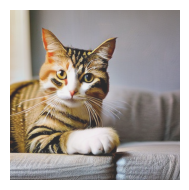

In [9]:
prompt = "a cat on a sofa"

prompt_embedding = get_text_embeddings(
    prompt=prompt,
    batch_size=1,  # type: ignore
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    with_grad=False,  # No gradients needed for initial image generation
)

image = generate_images_from_latents(
    init_latent,
    prompt_embedding,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
).squeeze()

prompt_embedding_jnp = jnp.array(prompt_embedding.detach().cpu().numpy(), dtype=jnp.float32)
show_image(image)

In [10]:
import jax
import jax.numpy as jnp

def _normalize(v, eps=1e-8):
    return v / (jnp.linalg.norm(v) + eps)

def _parse_indices(sel, n_comp: int) -> jnp.ndarray:
    """Parse singular-value indices (int | list[int] | slice | None) -> sorted unique jnp.int32."""
    if sel is None:
        return jnp.array([], dtype=jnp.int32)

    def _wrap(i):
        return i + n_comp if i < 0 else i

    if isinstance(sel, int):
        idx = [_wrap(sel)]
    elif isinstance(sel, slice):
        start = sel.start if sel.start is not None else 0
        stop  = sel.stop  if sel.stop  is not None else n_comp
        step  = sel.step  if sel.step  is not None else 1
        idx = list(range(start, stop, step))
    elif isinstance(sel, (list, tuple, jnp.ndarray)):
        idx = [_wrap(int(i)) for i in sel]
    else:
        raise ValueError(f"Unsupported selection type for select: {type(sel)}")

    idx = sorted(set([i for i in idx if 0 <= i < n_comp]))
    return jnp.array(idx, dtype=jnp.int32)

def _parse_batches(batch_select, B: int) -> jnp.ndarray:
    """
    batch_select can be:
      - 'auto' (default): if B==2, selects [1] (cond); else selects all [0..B-1]
      - 'all' or 'both': selects all batch rows
      - int or list/tuple of ints: explicit batch rows (supports negatives)
      - None: selects nothing (no change)
    """
    if batch_select is None:
        return jnp.array([], dtype=jnp.int32)

    if batch_select == 'auto':
        if B == 2:
            return jnp.array([1], dtype=jnp.int32)  # assume [uncond, cond]
        else:
            return jnp.arange(B, dtype=jnp.int32)
    if batch_select in ('all', 'both'):
        return jnp.arange(B, dtype=jnp.int32)

    # explicit indices
    if isinstance(batch_select, int):
        idx = [batch_select]
    elif isinstance(batch_select, (list, tuple, jnp.ndarray)):
        idx = list(batch_select)
    else:
        raise ValueError(f"Unsupported batch_select type: {type(batch_select)}")

    # wrap negatives and clip
    out = []
    for i in idx:
        i = int(i)
        if i < 0:
            i = B + i
        if 0 <= i < B:
            out.append(i)
    out = sorted(set(out))
    return jnp.array(out, dtype=jnp.int32)

def _svd_decompose(X: jnp.ndarray, center_tokens: bool):
    # X: (seq, dim)
    if center_tokens:
        X_mean = X.mean(axis=0, keepdims=True)
        Xc = X - X_mean
    else:
        X_mean = jnp.zeros((1, X.shape[1]), dtype=X.dtype)
        Xc = X
    U, S, Vt = jnp.linalg.svd(Xc, full_matrices=False)
    return U, S, Vt, X_mean

def _svd_reconstruct(U: jnp.ndarray, S: jnp.ndarray, Vt: jnp.ndarray, X_mean: jnp.ndarray):
    return (U * S) @ Vt + X_mean

def _svd_perturb_single(
    X: jnp.ndarray,                # (seq, dim)
    mode: str,
    select,                        # singular indices (int | list | slice | None)
    alpha: float,
    center_tokens: bool,
    seed: int,
):
    U, S, Vt, X_mean = _svd_decompose(X, center_tokens)
    n = S.shape[0]
    idx = _parse_indices(select, n)

    if idx.size == 0:
        return X.astype(jnp.float32)

    if mode == "sigma_scale":
        S_new = S.at[idx].set(S[idx] * (1.0 + alpha))
    elif mode == "sigma_shift":
        S_new = S.at[idx].set(S[idx] + alpha)
    elif mode == "v_mix":
        Vt_new = Vt
        for i in list(idx):
            key, sub = jax.random.split(key)
            vi = Vt_new[i]
            rand = jax.random.normal(sub, shape=vi.shape)
            rand_proj = rand - (jnp.dot(rand, vi) / (jnp.dot(vi, vi) + 1e-8)) * vi
            rand_dir = _normalize(rand_proj)
            mixed = _normalize(vi + alpha * rand_dir)
            Vt_new = Vt_new.at[i].set(mixed)
        Vt = Vt_new
        S_new = S
    else:
        raise ValueError(f"Unknown mode: {mode}")

    X_new = _svd_reconstruct(U, S_new, Vt, X_mean)
    return X_new.astype(jnp.float32)

def svd_perturb(
    prompt_emb_jnp: jnp.ndarray,    # (seq,dim) | (B,seq,dim)
    mode: str = "sigma_scale",      # "sigma_scale" | "sigma_shift" | "v_mix"
    select=None,                    # target singular indices (e.g., 0, [0,3], slice(0,2))
    alpha: float = 0.1,
    center_tokens: bool = False,
    seed: int = 0,
    batch_select='auto',            # which batch rows to perturb: 'auto'|'all'|int|list[int]|None
):
    """
    Supports embeddings with batch B:
      - If B==2 and batch_select='auto' (default), perturbs ONLY the cond embedding at index 1.
      - Use batch_select='all' to perturb both uncond & cond, or batch_select=0/1/[...] to target specific rows.
    """
    emb = prompt_emb_jnp
    if emb.ndim == 2:
        # (seq, dim)
        return _svd_perturb_single(emb, mode, select, alpha, center_tokens, seed)[None, ...]
    elif emb.ndim == 3:
        B, S, D = emb.shape
        targets = _parse_batches(batch_select, B)
        out = []
        for b in range(B):
            if (targets == b).any():
                out.append(_svd_perturb_single(emb[b], mode, select, alpha, center_tokens, seed + b))
            else:
                out.append(emb[b].astype(jnp.float32))
        return jnp.stack(out, axis=0)
    else:
        raise ValueError(f"Unexpected embedding shape: {emb.shape}")

alpha=0.6, 1th singular value


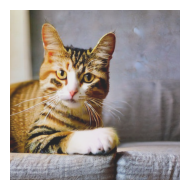

alpha=0.8, 1th singular value


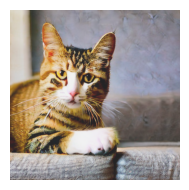

alpha=1.0, 1th singular value


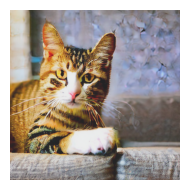

alpha=0.6, 2th singular value


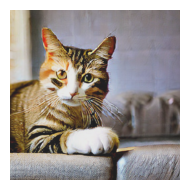

alpha=0.8, 2th singular value


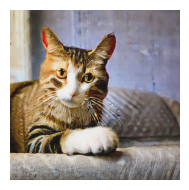

alpha=1.0, 2th singular value


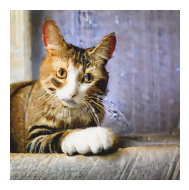

alpha=0.6, 3th singular value


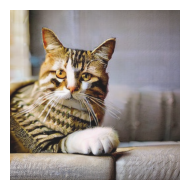

alpha=0.8, 3th singular value


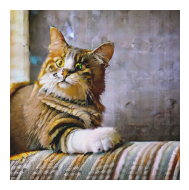

alpha=1.0, 3th singular value


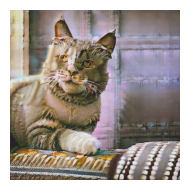

alpha=0.6, 4th singular value


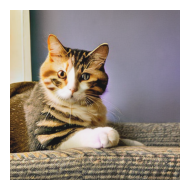

alpha=0.8, 4th singular value


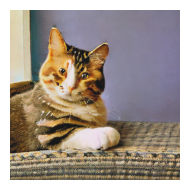

alpha=1.0, 4th singular value


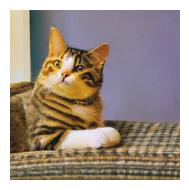

alpha=0.6, 5th singular value


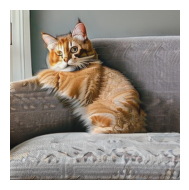

alpha=0.8, 5th singular value


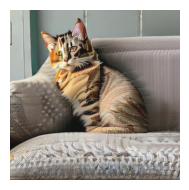

alpha=1.0, 5th singular value


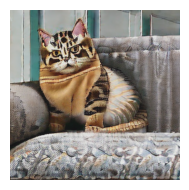

alpha=0.6, 6th singular value


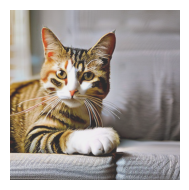

alpha=0.8, 6th singular value


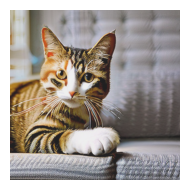

alpha=1.0, 6th singular value


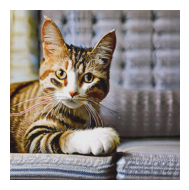

alpha=0.6, 7th singular value


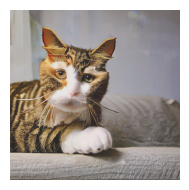

alpha=0.8, 7th singular value


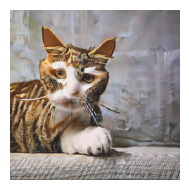

alpha=1.0, 7th singular value


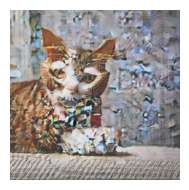

alpha=0.6, 8th singular value


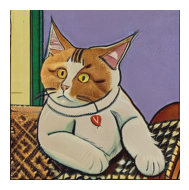

alpha=0.8, 8th singular value


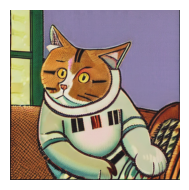

alpha=1.0, 8th singular value


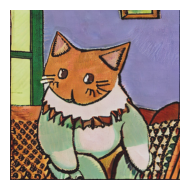

alpha=0.6, 9th singular value


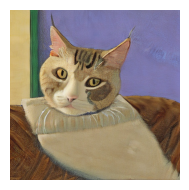

alpha=0.8, 9th singular value


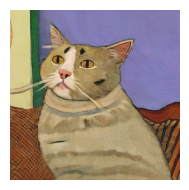

alpha=1.0, 9th singular value


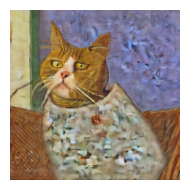

alpha=0.6, 10th singular value


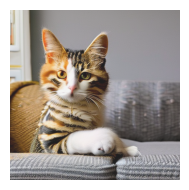

alpha=0.8, 10th singular value


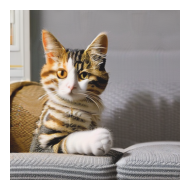

alpha=1.0, 10th singular value


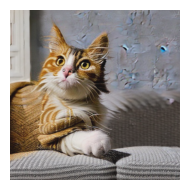

alpha=0.6, 11th singular value


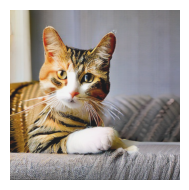

alpha=0.8, 11th singular value


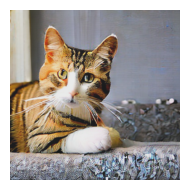

alpha=1.0, 11th singular value


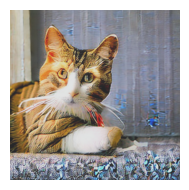

In [17]:
alphas = [0.6, 0.8, 1.0]
# # multiply ONLY the top singular value on the conditional embedding
# emb1 = svd_perturb(prompt_embedding_jnp, mode="sigma_scale", select=0, alpha=alpha, batch_select=1)

# # multiply the top TWO (0 and 1) on cond
# emb3 = svd_perturb(prompt_embedding_jnp, mode="sigma_scale", select=slice(0,2), alpha=alpha, batch_select=1)

# # add to the 2nd and 5th components on cond
# emb4 = svd_perturb(prompt_embedding_jnp, mode="sigma_shift", select=[1,4], alpha=alpha, batch_select=1)

# # tiny rotation of Vt on the 1st, 2nd, and 4th components on cond
# emb5 = svd_perturb(prompt_embedding_jnp, mode="v_mix", select=[0,1,3], alpha=alpha, seed=123, batch_select=1)

new_embeds = []
new_images = []
for n in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]:
    for alpha in alphas:
        print(f"alpha={alpha}, {n+1}th singular value")
        # multiply ONLY the nth singular value on cond
        new_embed = svd_perturb(prompt_embedding_jnp, mode="sigma_scale", select=n, alpha=alpha, batch_select=1)
        new_embeds.append(new_embed)
        img = generate_images_from_latents(
            init_latent,
            new_embed,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()
        show_image(img)
        new_images.append(img)

Descriptors: [[ -2.4405537  -10.275307  ]
 [ -6.9159393   -5.3875256 ]
 [ -7.7847457   -2.3838377 ]
 [ -5.8819304    7.765169  ]
 [  8.352553    -5.255884  ]
 [ 30.313288    -5.9648886 ]
 [ -2.8812609   -3.6258593 ]
 [ 11.674526   -12.795409  ]
 [ 26.489315   -18.712597  ]
 [  3.9506226   -8.209626  ]
 [  0.74417114 -14.254225  ]
 [ 15.206614   -17.005547  ]
 [  2.8487883   -5.200823  ]
 [  3.625268    11.7941265 ]
 [  5.4632735    6.491247  ]
 [  0.6889143  -11.730665  ]
 [  3.0622416   -6.7060843 ]
 [  3.2364569    3.1921692 ]
 [  7.191882     1.3556447 ]
 [ 10.197557    -0.15389633]
 [ 19.605635     9.320206  ]
 [ 37.84443    -24.950151  ]
 [ 14.470821   -12.741795  ]
 [ 16.892784   -17.995668  ]
 [ 20.172531   -20.269283  ]
 [  6.512389   -42.333836  ]
 [ 19.898876    -1.0305367 ]
 [  9.329784    -2.3997698 ]
 [  5.986947    -0.53982925]
 [  6.2623425   -1.9880552 ]
 [  0.3847723   -3.034665  ]
 [  3.2115345    0.07793331]
 [ 40.196754     1.6676264 ]]
Fitnesses: [0.30600265 0.2975

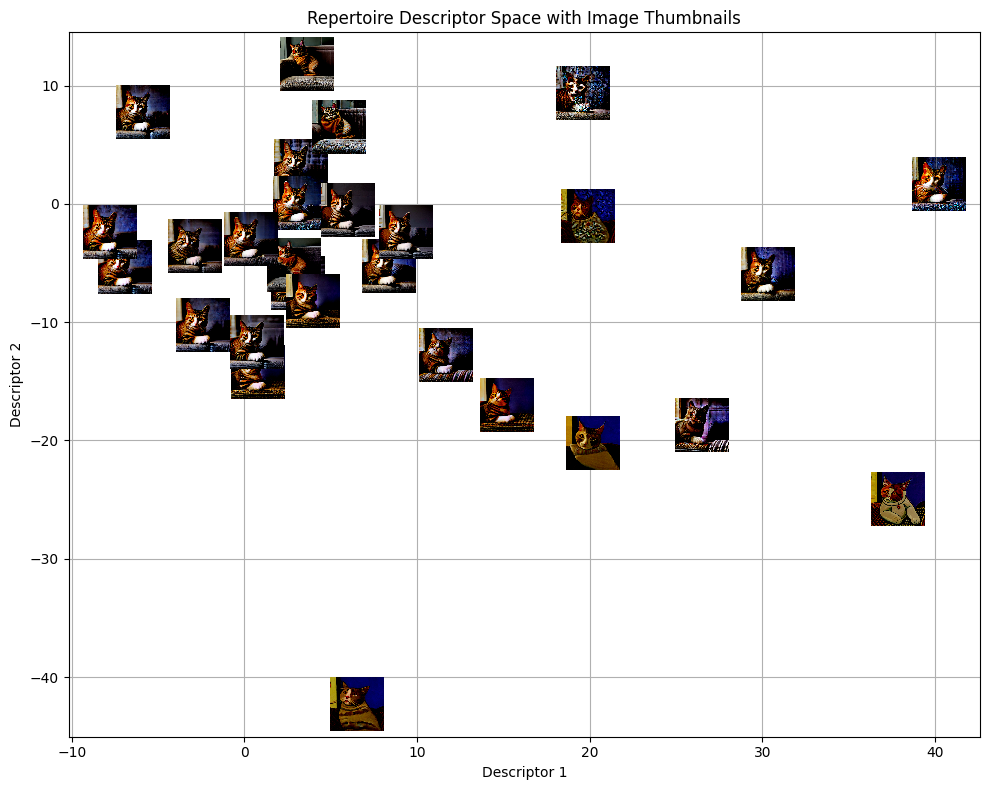

In [18]:
test_added_to_repertoire(
    new_embeds,
    prompt,
    key
)